In [204]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import stats
import datetime

In [205]:
import itables
itables.init_notebook_mode()
itables.options.style = "table-layout:auto;width:auto;margin:0;caption-side:bottom"
itables.options.allow_html = True

# Предзагрузка

In [206]:
# df_clients уже загружен выше (с корректными типами) в отдельной ячейке
df_transactions = pd.read_csv('../../data/transactions.csv', encoding='cp1251', sep=';')

In [207]:
df_transactions.to_csv('../../data/transactions_utf.csv', encoding='utf8')

## Клиенты

In [208]:
df_clients = pd.read_csv(
    '../../data/clients.csv',
    dtype={
        'client_id': 'string',
        # категориальные признаки
        'gender': 'category',
        'city': 'category',
        'segment': 'category',
        'loyalty_tier': 'category',
        'card_type': 'category',
        'income_source': 'category',
        'has_mobile_app': 'category',
        'marketing_opt_in': 'category',
        # числовые признаки
        'monthly_income': 'float64',
        'satisfaction_score': 'Int64',   # 1..5, есть пропуски -> nullable int
        'branch_code': 'int64',
        # даты читаем как строки и парсим отдельно (форматы разные)
        'birth_date': 'string',
        'registration_date': 'string',
        'card_open_date': 'string',
        'app_last_login': 'string',
    },
)

df_clients['birth_date']        = pd.to_datetime(df_clients['birth_date'],        format='%Y-%m-%d')
df_clients['registration_date'] = pd.to_datetime(df_clients['registration_date'], format='%d.%m.%Y')
df_clients['card_open_date']    = pd.to_datetime(df_clients['card_open_date'],    format='%d.%m.%Y')
df_clients['app_last_login']    = pd.to_datetime(df_clients['app_last_login'],    format='%Y-%m', errors='coerce')

df_clients

client_id birth_date gender             city      segment loyalty_tier  \
0      C002786 1960-11-04      Ж           Казань     Массовый      Базовый   
1      C003601 1988-05-11      Ж           Казань     Массовый      Базовый   
2      C003692 1976-10-16      Ж              СПб  Премиальный      Серебро   
3      C005100 1983-02-13      Ж      Н. Новгород   Зарплатный      Базовый   
4      C001633 1976-05-24      М  Нижний Новгород     Массовый      Базовый   
...        ...        ...    ...              ...          ...          ...   
5714   C005672 1973-06-03      М     Екатеринбург     Массовый      Базовый   
5715   C001251 1954-04-22      Ж           МОСКВА     Массовый       Золото   
5716   C004957 1985-12-04      Ж              СПб  Премиальный       Золото   
5717   C002479 1965-05-27      Ж  Санкт Петербург   Зарплатный      Платина   
5718   C002940 1968-05-27      Ж           Казань  Премиальный       Золото   

        card_type registration_date card_open_date            income_source  \
0       Дебетовая        2021-03-02     2023-06-22  Зарплата в другом банке   
1       Дебетовая        2022-12-09     2025-02-21   Зарплата в нашем банке   
2       Дебетовая        2014-09-18     2018-04-25   Зарплата в нашем банке   
3       Кредитная        2019-10-26     2025-03-18   Зарплата в нашем банке   
4       Дебетовая        2018-04-20     2021-09-14  Зарплата в другом банке   
...           ...               ...            ...                      ...   
5714    Дебетовая        2017-09-16     2018-03-08   Зарплата в нашем банке   
5715    Дебетовая        2020-03-26     2021-07-16                Не указан   
5716    Дебетовая        2015-09-02     2018-06-15   Зарплата в нашем банке   
5717    Дебетовая        2014-01-06     2017-08-08   Зарплата в нашем банке   
5718  Премиальная        2018-05-03     2022-06-11                Не указан   

      monthly_income has_mobile_app app_last_login  satisfaction_score  \
0            52500.0            Нет            NaT                   5   
1            57600.0            Нет            NaT                <NA>   
2           105300.0             Да     2025-03-01                <NA>   
3            94800.0             Да     2025-03-01                <NA>   
4            47700.0             Да     2025-03-01                   2   
...              ...            ...            ...                 ...   
5714         72400.0             Да     2025-01-01                <NA>   
5715         55200.0            Нет            NaT                <NA>   
5716         77200.0             Да     2025-06-01                <NA>   
5717        111800.0            Нет            NaT                   3   
5718             NaN             Да     2024-12-01                   5   

      branch_code marketing_opt_in  
0             905               Да  
1             635              Нет  
2             872               Да  
3             443               Да  
4             598               Да  
...           ...              ...  
5714          539               Да  
5715          843               Да  
5716          589               Да  
5717          424               Да  
5718          453               Да  

[5719 rows x 16 columns]

In [209]:
df_clients.info()

<class 'pandas.DataFrame'>
RangeIndex: 5719 entries, 0 to 5718
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5719 non-null   string        
 1   birth_date          5719 non-null   datetime64[us]
 2   gender              5719 non-null   category      
 3   city                5719 non-null   category      
 4   segment             5719 non-null   category      
 5   loyalty_tier        5719 non-null   category      
 6   card_type           5719 non-null   category      
 7   registration_date   5719 non-null   datetime64[us]
 8   card_open_date      5719 non-null   datetime64[us]
 9   income_source       5719 non-null   category      
 10  monthly_income      5194 non-null   float64       
 11  has_mobile_app      5719 non-null   category      
 12  app_last_login      3501 non-null   datetime64[us]
 13  satisfaction_score  2246 non-null   Int64         
 14  bra

In [210]:
df_clients.describe(include=['int', 'float']).style.format('{:.2f}')

In [211]:
df_clients.describe(include='datetime')

birth_date           registration_date  \
count                        5719                        5719   
mean   1971-11-01 10:26:57.765343  2017-08-22 15:20:48.260185   
min           1936-07-26 00:00:00         2010-01-27 00:00:00   
25%           1962-12-27 00:00:00         2015-04-19 12:00:00   
50%           1973-07-23 00:00:00         2017-08-02 00:00:00   
75%           1982-06-05 12:00:00         2020-02-01 00:00:00   
max           2001-11-09 00:00:00         2025-04-01 00:00:00   

                   card_open_date              app_last_login  
count                        5719                        3501  
mean   2020-09-02 05:24:33.614268  2024-09-20 11:38:49.048843  
min           2016-01-01 00:00:00         2024-01-01 00:00:00  
25%           2018-03-26 00:00:00         2024-05-01 00:00:00  
50%           2020-09-09 00:00:00         2024-10-01 00:00:00  
75%           2022-12-20 12:00:00         2025-02-01 00:00:00  
max           2025-05-16 00:00:00         2025-06-01 00:00:00

In [212]:
df_clients.describe(include='category')

gender    city   segment loyalty_tier  card_type  \
count    5719    5719      5719         5719       5719   
unique      2      17         4            4          3   
top         Ж  Москва  Массовый      Базовый  Дебетовая   
freq     2902    1094      2867         2877       3947   

                 income_source has_mobile_app marketing_opt_in  
count                     5719           5719             5719  
unique                       3              2                2  
top     Зарплата в нашем банке             Да               Да  
freq                      2637           3501             5035

<Axes: title={'center': 'Missing Values in Clients DataFrame'}>

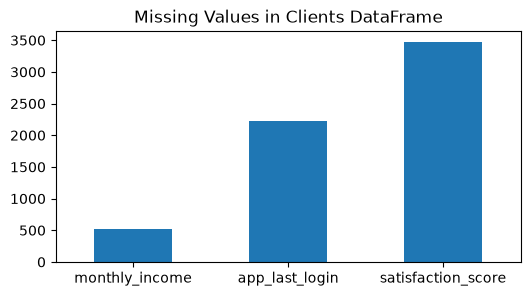

In [213]:
missing = df_clients.isnull().sum()
missing[missing > 0].plot(kind='bar', figsize=(6, 3), title='Missing Values in Clients DataFrame', rot=0)

## Транзакции

In [214]:
df_transactions.info()

<class 'pandas.DataFrame'>
RangeIndex: 625276 entries, 0 to 625275
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   txn_id        625276 non-null  int64
 1   client_id     625276 non-null  str  
 2   txn_datetime  625276 non-null  str  
 3   amount        625276 non-null  str  
 4   currency      625276 non-null  str  
 5   category      625276 non-null  str  
 6   mcc_code      625276 non-null  int64
 7   channel       625276 non-null  str  
 8   status        625276 non-null  str  
dtypes: int64(2), str(7)
memory usage: 42.9 MB


In [215]:
df_transactions.head(10)

txn_id client_id         txn_datetime   amount currency        category  \
0  990163   C001976           2023-12-10  4638,38      RUB  Одежда и обувь   
1  990199   C004215  2023-12-12 12:19:56   507,22      RUB        Продукты   
2  990072   C004029  2023-12-17 13:59:08   902,94      RUB        Продукты   
3  990033   C001144  2023-12-17 14:36:01   247,73      RUB        Продукты   
4  990046   C001369  2023-12-28 06:54:01   135,79      RUB       Транспорт   
5  990031   C005193  2023-12-29 13:54:01  1477,23      RUB  Одежда и обувь   
6  100001   C005305  2024-01-01 01:50:44   304,36      RUB        Продукты   
7  100002   C004634  2024-01-01 02:03:31   3652,1      RUB             АЗС   
8  100003   C002342  2024-01-01 02:59:15  3027,03      RUB        Продукты   
9  100004   C000771  2024-01-01 03:06:04  2880,79      RUB  Кафе/рестораны   

   mcc_code channel   status  
0      5651   Карта  успешно  
1      5411   Карта  успешно  
2      5411   Карта  успешно  
3      5411   Карта  успешно  
4      4111   Карта  успешно  
5      5651     СБП  успешно  
6      5411   Карта  успешно  
7      5541     СБП  успешно  
8      5411   Карта  успешно  
9      5812   Карта  успешно

In [216]:
df_transactions.isnull().sum().to_frame().T

txn_id  client_id  txn_datetime  amount  currency  category  mcc_code  \
0       0          0             0       0         0         0         0   

   channel  status  
0        0       0

In [217]:
df_transactions.columns

Index(['txn_id', 'client_id', 'txn_datetime', 'amount', 'currency', 'category',
       'mcc_code', 'channel', 'status'],
      dtype='str')

In [218]:
df_transactions = pd.read_csv(
    '../../data/transactions.csv',
    dtype={
        'txn_id': 'Int64',
        'client_id': 'string',
        'txn_datetime': 'string',
        'amount': 'string',
        'currency': 'category',
        'category': 'category',
        'mcc_code': 'Int64',
        'channel': 'category',
        'status': 'category',
    },
     encoding='cp1251', sep=';'
)

df_transactions['txn_datetime']    = pd.to_datetime(df_transactions['txn_datetime'], errors='coerce', format='mixed')
df_transactions['amount'] = df_transactions['amount'].str.replace(",", ".").astype('float64')

df_transactions

txn_id client_id        txn_datetime   amount currency  \
0       990163   C001976 2023-12-10 00:00:00  4638.38      RUB   
1       990199   C004215 2023-12-12 12:19:56   507.22      RUB   
2       990072   C004029 2023-12-17 13:59:08   902.94      RUB   
3       990033   C001144 2023-12-17 14:36:01   247.73      RUB   
4       990046   C001369 2023-12-28 06:54:01   135.79      RUB   
...        ...       ...                 ...      ...      ...   
625271  990152   C001912 2026-06-24 16:19:11  1060.70      RUB   
625272  990194   C001002 2026-07-09 09:25:04  3045.29      RUB   
625273  990206   C001650 2026-07-15 10:58:41  9107.46      RUB   
625274  990054   C005540 2026-07-23 10:34:51   813.12      RUB   
625275  990138   C004334 2026-08-01 14:07:43  1641.76      RUB   

                   category  mcc_code channel     status  
0            Одежда и обувь      5651   Карта    успешно  
1                  Продукты      5411   Карта    успешно  
2                  Продукты      5411   Карта    успешно  
3                  Продукты      5411   Карта    успешно  
4                 Транспорт      4111   Карта    успешно  
...                     ...       ...     ...        ...  
625271  Развлечения и досуг      7832   Карта    успешно  
625272       Одежда и обувь      5651   Токен    успешно  
625273       Одежда и обувь      5651   Карта    успешно  
625274                  АЗС      5541   Карта  отклонено  
625275  Развлечения и досуг      7832   Токен    успешно  

[625276 rows x 9 columns]

# Дубликаты

## Клиенты

In [219]:
df_clients['client_id'].nunique()


5664

In [220]:
df_clients.shape[0]

5719

In [221]:
df_clients[df_clients.duplicated(keep=False)].sort_values(by='client_id').head(6)


client_id birth_date gender    city      segment loyalty_tier  \
3457   C000086 1971-08-14      Ж  Москва      Private       Золото   
3794   C000086 1971-08-14      Ж  Москва      Private       Золото   
1562   C000120 1977-05-10      Ж  Москва     Массовый      Базовый   
4677   C000120 1977-05-10      Ж  Москва     Массовый      Базовый   
5498   C000196 1966-08-01      Ж  Москва  Премиальный      Базовый   
2516   C000196 1966-08-01      Ж  Москва  Премиальный      Базовый   

        card_type registration_date card_open_date            income_source  \
3457    Кредитная        2016-04-26     2019-03-11   Зарплата в нашем банке   
3794    Кредитная        2016-04-26     2019-03-11   Зарплата в нашем банке   
1562    Дебетовая        2015-10-06     2019-11-15   Зарплата в нашем банке   
4677    Дебетовая        2015-10-06     2019-11-15   Зарплата в нашем банке   
5498  Премиальная        2015-05-18     2021-03-03  Зарплата в другом банке   
2516  Премиальная        2015-05-18     2021-03-03  Зарплата в другом банке   

      monthly_income has_mobile_app app_last_login  satisfaction_score  \
3457        447900.0             Да     2025-04-01                <NA>   
3794        447900.0             Да     2025-04-01                <NA>   
1562         66000.0             Да     2025-05-01                <NA>   
4677         66000.0             Да     2025-05-01                <NA>   
5498        241700.0            Нет            NaT                   2   
2516        241700.0            Нет            NaT                   2   

      branch_code marketing_opt_in  
3457          859               Да  
3794          859               Да  
1562          648               Да  
4677          648               Да  
5498          208               Да  
2516          208               Да

In [222]:
df_clients.duplicated(keep=False).sum()

np.int64(80)

In [223]:
df_clients.duplicated(subset=['client_id'], keep=False).sum()

np.int64(110)

In [224]:
df_clients = df_clients.drop_duplicates()

In [225]:
df_clients[df_clients['client_id'].duplicated(keep=False)].sort_values('client_id')

client_id birth_date gender                city      segment  \
335    C000317 1974-12-31      М  г. Санкт-Петербург   Зарплатный   
5152   C000317 1974-12-31      М        Екатеринбург      Private   
4859   C000490 1982-09-01      Ж         Н. Новгород     Массовый   
2993   C000490 1982-09-01      Ж     Нижний Новгород  Премиальный   
2174   C000501 1968-11-03      М        Екатеринбург     Массовый   
1435   C000501 1968-11-03      М              Казань     Массовый   
2943   C000608 1989-09-05      М      г. Новосибирск  Премиальный   
2873   C000608 1989-09-05      М              Казань      Private   
3823   C001338 1951-05-30      Ж     Нижний Новгород   Зарплатный   
5332   C001338 1951-05-30      Ж         Новосибирск  Премиальный   
4749   C001467 1967-07-24      Ж        Екатеринбург     Массовый   
2797   C001467 1967-07-24      Ж        Екатеринбург      Private   
1166   C001873 1989-04-16      М      г. Новосибирск  Премиальный   
525    C001873 1989-04-16      М        Екатеринбург      Private   
1461   C002087 1980-05-05      М         Новосибирск     Массовый   
1632   C002087 1980-05-05      М        Екатеринбург      Private   
2431   C002243 1976-10-29      М              Казань     Массовый   
4688   C002243 1976-10-29      М              Казань      Private   
4858   C002270 1983-05-22      М     Санкт-Петербург     Массовый   
4468   C002270 1983-05-22      М              Казань  Премиальный   
5680   C002597 1991-11-20      Ж              Казань   Зарплатный   
992    C002597 1991-11-20      Ж     Санкт-Петербург     Массовый   
2224   C002951 1946-09-06      М     Нижний Новгород     Массовый   
1989   C002951 1946-09-06      М        Екатеринбург   Зарплатный   
5547   C003148 1956-10-27      Ж     Санкт-Петербург   Зарплатный   
1394   C003148 1956-10-27      Ж              МОСКВА      Private   
3584   C003209 1955-12-29      М              Москва  Премиальный   
256    C003209 1955-12-29      М     Санкт-Петербург     Массовый   
2936   C004216 1991-04-13      Ж              Москва      Private   
2455   C004216 1991-04-13      Ж     Санкт Петербург  Премиальный   

     loyalty_tier    card_type registration_date card_open_date  \
335       Базовый    Дебетовая        2021-06-08     2023-02-21   
5152      Базовый    Дебетовая        2021-06-08     2023-02-21   
4859      Серебро    Дебетовая        2020-09-01     2023-10-10   
2993      Серебро    Дебетовая        2020-09-01     2023-10-10   
2174      Базовый    Дебетовая        2013-01-15     2017-08-17   
1435      Базовый    Дебетовая        2013-01-15     2017-08-17   
2943      Серебро    Дебетовая        2020-09-12     2024-08-01   
2873      Серебро    Дебетовая        2020-09-12     2024-08-01   
3823      Серебро    Дебетовая        2019-04-17     2020-02-18   
5332      Серебро    Дебетовая        2019-04-17     2020-02-18   
4749      Базовый    Дебетовая        2019-01-27     2020-05-26   
2797      Базовый    Дебетовая        2019-01-27     2020-05-26   
1166       Золото  Премиальная        2023-12-25     2025-03-30   
525        Золото  Премиальная        2023-12-25     2025-03-30   
1461      Базовый    Дебетовая        2019-06-22     2024-07-14   
1632      Базовый    Дебетовая        2019-06-22     2024-07-14   
2431      Базовый    Кредитная        2017-05-29     2018-08-20   
4688      Базовый    Кредитная        2017-05-29     2018-08-20   
4858       Золото  Премиальная        2016-11-21     2021-06-21   
4468       Золото  Премиальная        2016-11-21     2021-06-21   
5680      Базовый    Дебетовая        2019-12-17     2021-06-01   
992       Базовый    Дебетовая        2019-12-17     2021-06-01   
2224      Базовый    Кредитная        2016-10-12     2016-11-17   
1989      Базовый    Кредитная        2016-10-12     2016-11-17   
5547      Платина    Кредитная        2019-09-29     2021-09-10   
1394      Платина    Кредитная        2019-09-29     2021-09-10   
3584      Базовый    Дебетовая        2018-06-13     202

In [226]:
messy_clients_duplicates_mask = df_clients['client_id'].duplicated(keep=False)
messy_clients_duplicates = df_clients[messy_clients_duplicates_mask]
df_clients = df_clients[~messy_clients_duplicates_mask]

## Транзакции

In [227]:
df_transactions.duplicated(keep=False).sum()

np.int64(2562)

In [228]:
df_transactions = df_transactions.drop_duplicates(keep='first')

In [229]:
df_transactions.duplicated(subset = ['txn_id'], keep=False).sum()

np.int64(438)

In [230]:
(df_transactions[
    df_transactions.duplicated(subset = ['client_id', 'txn_datetime'], keep=False)
    & 
    (df_transactions['txn_datetime'].dt.time == datetime.time(0, 0))]
    .sort_values(by = 'client_id'))

txn_id client_id txn_datetime   amount currency             category  \
28366   128285   C000006   2024-02-02  4284.67      RUB  Развлечения и досуг   
27844   127765   C000006   2024-02-02   124.99      RUB       Онлайн-сервисы   
79484   179280   C000007   2024-03-16   352.40      RUB             Продукты   
79224   179021   C000007   2024-03-16  1303.35      RUB             Продукты   
411923  510854   C000011   2024-12-07  6685.31      RUB  Развлечения и досуг   
...        ...       ...          ...      ...      ...                  ...   
261891  361207   C005954   2024-08-12   207.57      RUB     Связь и интернет   
131061  230705   C005977   2024-04-26  2819.78      RUB     Кафе и рестораны   
130553  230200   C005977   2024-04-26   281.24      RUB       Онлайн-сервисы   
208363  307806   C005996   2024-07-01   187.33      RUB            Транспорт   
208627  308067   C005996   2024-07-01  6043.47      RUB                  АЗС   

        mcc_code      channel   status  
28366       7832        Карта  успешно  
27844       5815          СБП  успешно  
79484       5411        Карта  успешно  
79224       5411        Карта  успешно  
411923      7832        Токен  успешно  
...          ...          ...      ...  
261891      4814        Карта  успешно  
131061      5812        Карта  успешно  
130553      5815        Карта  успешно  
208363      4111  Онлайн-банк  успешно  
208627      5541        Карта  успешно  

[1342 rows x 9 columns]

In [231]:
(df_transactions[
    df_transactions.duplicated(subset = ['txn_id'], keep=False)]
    .sort_values(by = 'client_id'))

txn_id client_id        txn_datetime   amount currency  \
293852  393074   C000018 2024-09-06 00:00:00  3784.60      RUB   
293853  393074   C000018 2024-09-06 21:17:25  3784.60      RUB   
13451   113409   C000019 2024-01-16 00:00:00  1264.30      RUB   
13452   113409   C000019 2024-01-16 17:20:35  1264.30      RUB   
446503  545334   C000022 2024-12-30 14:54:06  3568.72      RUB   
...        ...       ...                 ...      ...      ...   
441758  540602   C005912 2024-12-27 00:00:00   390.52      RUB   
396274  495242   C005925 2024-11-27 08:37:42   230.70      RUB   
396273  495242   C005925 2024-11-27 00:00:00   230.70      RUB   
395773  494744   C005933 2024-11-26 15:46:24  1411.92      RUB   
395772  494744   C005933 2024-11-26 00:00:00  1411.92      RUB   

                   category  mcc_code channel   status  
293852  Развлечения и досуг      7832   Карта  успешно  
293853  Развлечения и досуг      7832   Карта  успешно  
13451   Развлечения и досуг      7832   Карта  успешно  
13452   Развлечения и досуг      7832   Карта  успешно  
446503  Развлечения и досуг      7832   Карта  успешно  
...                     ...       ...     ...      ...  
441758       Онлайн-сервисы      5815   Карта  успешно  
396274            Транспорт      4111   Карта  успешно  
396273            Транспорт      4111   Карта  успешно  
395773             Продукты      5411   Карта  успешно  
395772             Продукты      5411   Карта  успешно  

[438 rows x 9 columns]

In [232]:
df_transactions.duplicated(subset = ['txn_id'], keep=False).sum()

np.int64(438)

In [233]:
df_transactions[
    df_transactions.duplicated(subset = ['txn_id'], keep=False)
    & 
    (df_transactions['txn_datetime'].dt.time == datetime.time(0, 0))]['txn_id'].unique().shape

(219,)

In [234]:
no_time_txn_duplicates_mask = (df_transactions.duplicated(subset = ['txn_id'], keep=False)
    & 
    (df_transactions['txn_datetime'].dt.time == datetime.time(0, 0)))
df_transactions = df_transactions[~no_time_txn_duplicates_mask]

In [235]:
df_transactions.duplicated(subset = ['txn_id'], keep=False).sum()

np.int64(0)

# Copy

In [236]:
df_clients_full = df_clients.copy()
df_transactions_full = df_transactions.copy()

# Поля

## Клиенты

In [237]:
common_mask = df_clients['client_id'].isin(df_transactions['client_id'])
# n_common = common_mask.sum()
# n_unique_common = df_transactions.loc[common_mask, 'client_id'].nunique()

print(f'Число уникальных клиентов в clients.csv: {df_clients['client_id'].unique().shape[0]}')
print(f'Число уникальных клиентов в transactions.csv: {df_transactions['client_id'].unique().shape[0]}')
print(f'Их пересечение: {common_mask.sum()}')

Число уникальных клиентов в clients.csv: 5649
Число уникальных клиентов в transactions.csv: 5985
Их пересечение: 5634


In [238]:
df_clients = df_clients[common_mask]
# tnx_common_mask = df_transactions['client_id'].isin(df_clients['client_id'])
# df_transactions = df_transactions[tnx_common_mask]
# print(df_transactions.shape)

### Города

In [239]:
df_clients['city'].unique()

['Казань', 'СПб', 'Н. Новгород', 'Нижний Новгород', 'г. Москва', ..., 'казань', 'г. Санкт-Петербург', 'Санкт Петербург', 'МОСКВА', 'г. Новосибирск']
Length: 17
Categories (17, str): [' москва', 'ЕКАТЕРИНБУРГ', 'Екатеринбург', 'Казань', ..., 'г. Новосибирск', 'г. Санкт-Петербург', 'г.Екатеринбург', 'казань']

In [240]:
city_aliases = {
        'Москва': [' москва', 'МОСКВА', 'г. Москва', 'Москва'],
        'Санкт-Петербург': ['г. Санкт-Петербург', 'СПб', 'Санкт-Петербург', 'Санкт Петербург'],
        'Екатеринбург': ['г.Екатеринбург', 'Екатеринбург', 'ЕКАТЕРИНБУРГ'],
        'Казань': ['Казань', 'казань'],
        'Нижний Новгород': ['Нижний Новгород', 'Н. Новгород'],
        'Новосибирск': ['г. Новосибирск', 'Новосибирск'],
    }
reverse_city_aliases = {alias: city for city, aliases in city_aliases.items() for alias in aliases}

def city_name(city_name):
    return reverse_city_aliases.get(city_name, city_name)

df_clients['city'] = df_clients['city'].apply(city_name)

<Axes: title={'center': 'City Distribution'}, xlabel='city'>

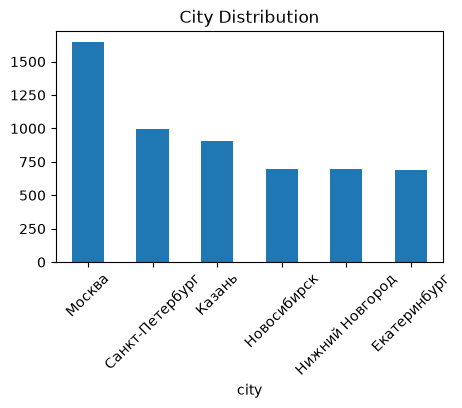

In [241]:
df_clients['city'].value_counts().plot(kind='bar', figsize=(5, 3), title='City Distribution', rot=45)

### Дата рождения

In [242]:
df_clients['birth_date'].describe()

count                          5634
mean     1971-11-07 21:49:54.249201
min             1936-07-26 00:00:00
25%             1963-01-11 12:00:00
50%             1973-07-28 12:00:00
75%             1982-05-29 00:00:00
max             2001-11-09 00:00:00
Name: birth_date, dtype: object

<Axes: >

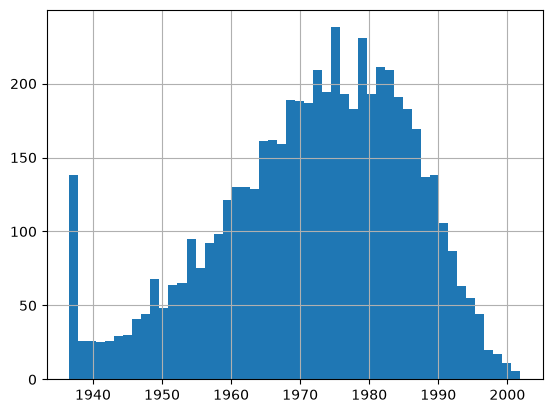

In [243]:
df_clients['birth_date'].hist(bins = 50)

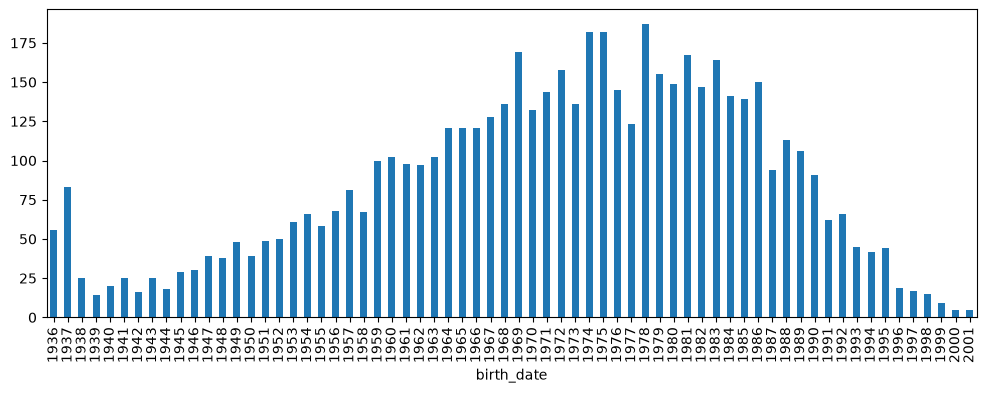

In [244]:
vc = df_clients['birth_date'].dt.year.value_counts().sort_index().plot.bar(figsize=(12, 4))

# vc.plot(kind='bar', figsize=(12, 4), edgecolor='black')

In [245]:
# Посмотрим топ-10 самых частых дат рождения
df_clients['birth_date'].value_counts().head(10)

birth_date
1975-07-08    6
1974-10-07    4
1966-02-05    4
1982-10-28    4
1978-01-20    3
1972-12-31    3
1989-03-23    3
1976-10-22    3
1959-01-02    3
1979-06-28    3
Name: count, dtype: int64

In [246]:
pd.crosstab(df_clients['satisfaction_score'], df_clients['birth_date'].dt.year > 1938, colnames=['Родились после 38'])

Родились после 38   False  True 
satisfaction_score              
1                      12    266
2                      11    415
3                      13    416
4                      14    453
5                      12    598

In [247]:
(df_clients['birth_date'].dt.year < 1941).sum()/df_clients.shape[0]

np.float64(0.03514376996805112)

In [248]:
tnx_old = df_transactions['client_id'].isin(df_clients[df_clients['birth_date'].dt.year < 1941]['client_id'])
tnx_old.sum()/tnx_old.shape[0]

np.float64(0.02298100600215462)

### Дата регистрации

<Axes: >

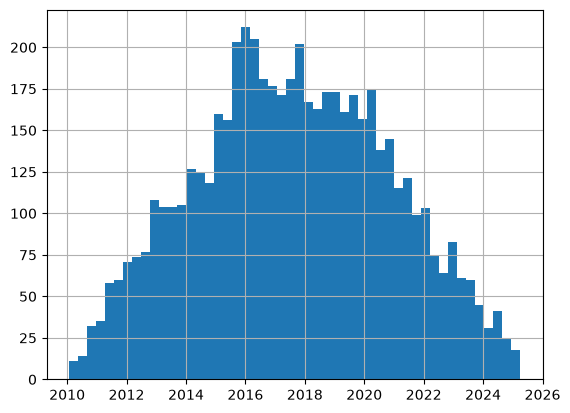

In [249]:
df_clients['registration_date'].hist(bins = 50)

### Гендер

<Axes: xlabel='gender'>

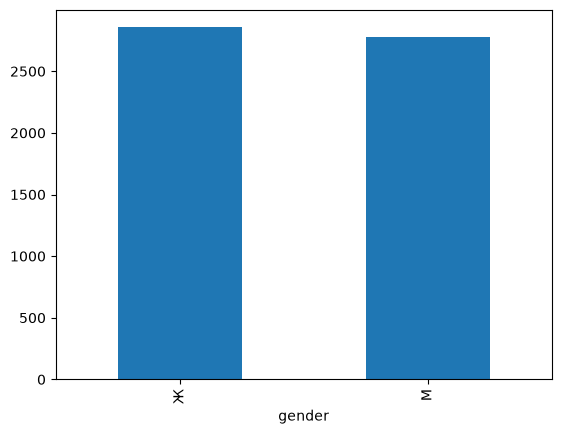

In [250]:
df_clients['gender'].value_counts().plot.bar()

### Сегмент

<Axes: xlabel='segment'>

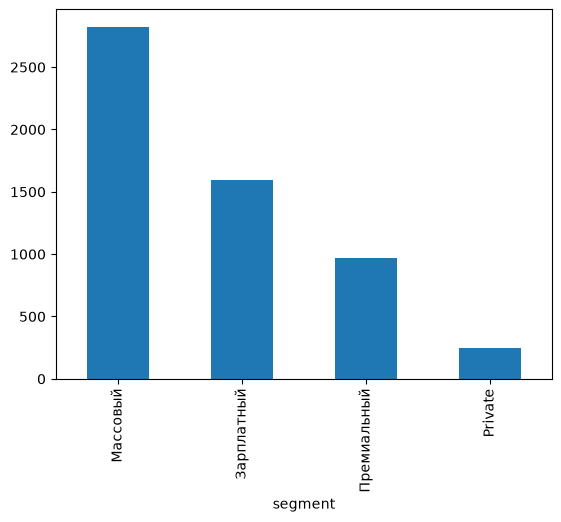

In [251]:
df_clients['segment'].value_counts().plot.bar()

In [252]:
pd.crosstab(df_clients['segment'], df_clients['card_type'])

card_type    Дебетовая  Кредитная  Премиальная
segment                                       
Private             49         33          162
Зарплатный        1147        408           40
Массовый          2277        520           26
Премиальный        422        253          297

### Тип карты

<Axes: xlabel='card_type'>

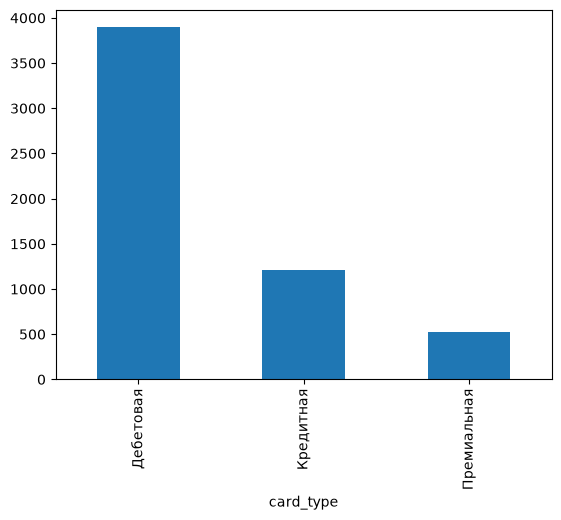

In [253]:
df_clients['card_type'].value_counts().plot.bar()

### Уровень лояльности

<Axes: xlabel='loyalty_tier'>

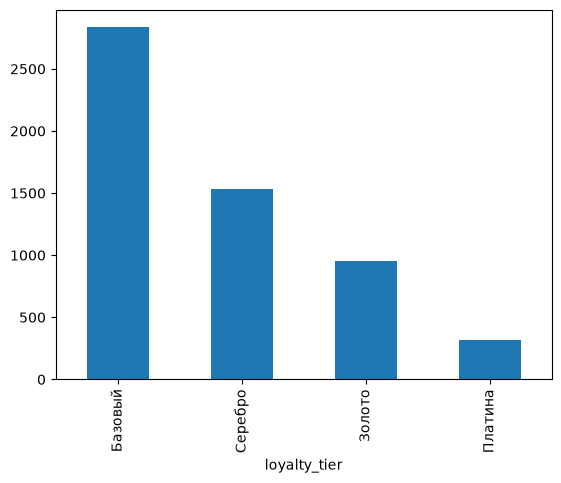

In [254]:
df_clients['loyalty_tier'].value_counts().plot.bar()

In [255]:
(pd.crosstab(df_clients['loyalty_tier'], df_clients['segment'], normalize = 'all', margins=True) * 100).round(2)

segment       Private  Зарплатный  Массовый  Премиальный     All
loyalty_tier                                                    
Базовый          0.14       12.97     35.11         2.08   50.30
Золото           1.67        4.53      3.73         6.99   16.92
Платина          2.15        0.76      0.48         2.24    5.63
Серебро          0.37       10.05     10.79         5.95   27.16
All              4.33       28.31     50.11        17.25  100.00

In [256]:
(pd.crosstab(df_clients['loyalty_tier'], df_clients['card_type'], normalize = True, margins=True) * 100).round(2)

card_type     Дебетовая  Кредитная  Премиальная     All
loyalty_tier                                           
Базовый           38.66      10.31         1.33   50.30
Золото             9.30       4.21         3.41   16.92
Платина            2.34       1.12         2.17    5.63
Серебро           18.83       5.91         2.41   27.16
All               69.13      21.55         9.32  100.00

### Дата открытия карты

<Axes: >

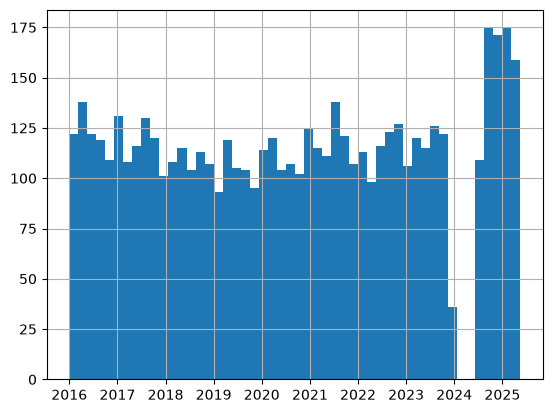

In [257]:
df_clients['card_open_date'].hist(bins = 50)

In [258]:
((df_clients['card_open_date'].dt.year == 2024) & (df_clients['card_open_date'].dt.month < 7)).sum()

np.int64(0)

In [259]:
df_clients[df_clients['card_open_date'].dt.year == 2024].sort_values(by='card_open_date')

client_id birth_date gender             city      segment loyalty_tier  \
570    C003053 1960-05-02      М  Санкт-Петербург   Зарплатный      Серебро   
4815   C005504 1979-08-30      Ж           Москва     Массовый      Базовый   
901    C005123 1988-01-19      М           Казань     Массовый      Базовый   
3381   C004587 1973-01-07      М           Москва  Премиальный      Платина   
3920   C001001 1968-01-10      Ж           Москва   Зарплатный      Серебро   
...        ...        ...    ...              ...          ...          ...   
2134   C000428 1980-07-24      М     Екатеринбург  Премиальный      Серебро   
3090   C002144 1986-07-02      Ж      Новосибирск     Массовый      Базовый   
2865   C005663 1942-02-26      М           Москва   Зарплатный      Серебро   
3312   C004432 1969-06-16      Ж           Москва     Массовый      Серебро   
106    C002567 1959-06-29      М           Москва     Массовый      Базовый   

        card_type registration_date card_open_date            income_source  \
570     Дебетовая        2024-06-06     2024-07-01   Зарплата в нашем банке   
4815    Дебетовая        2022-07-11     2024-07-01  Зарплата в другом банке   
901     Дебетовая        2020-12-24     2024-07-02  Зарплата в другом банке   
3381  Премиальная        2019-09-05     2024-07-02   Зарплата в нашем банке   
3920    Кредитная        2023-01-08     2024-07-05   Зарплата в нашем банке   
...           ...               ...            ...                      ...   
2134  Премиальная        2020-08-09     2024-12-27   Зарплата в нашем банке   
3090    Кредитная        2022-06-27     2024-12-30                Не указан   
2865    Кредитная        2019-08-03     2024-12-31   Зарплата в нашем банке   
3312    Дебетовая        2020-05-14     2024-12-31                Не указан   
106     Дебетовая        2021-03-20     2024-12-31                Не указан   

      monthly_income has_mobile_app app_last_login  satisfaction_score  \
570          59000.0             Да     2024-11-01                   3   
4815         77800.0             Да     2025-06-01                   2   
901             71.8             Да     2024-05-01                   3   
3381        138300.0             Да     2024-11-01                <NA>   
3920         74900.0             Да     2024-12-01                <NA>   
...              ...            ...            ...                 ...   
2134        217600.0            Нет            NaT                   3   
3090         64700.0             Да     2025-06-01                   2   
2865        110800.0            Нет            NaT                <NA>   
3312         51800.0             Да     2024-07-01                <NA>   
106          57700.0             Да     2025-02-01                <NA>   

      branch_code marketing_opt_in  
570           397               Да  
4815          129               Да  
901           896               Да  
3381          545               Да  
3920          422              Нет  
...           ...              ...  
2134          138               Да  
3090          609               Да  
2865          204               Да  
3312          773               Да  
106           719               Да  

[458 rows x 16 columns]

### Источник дохода

<Axes: xlabel='income_source'>

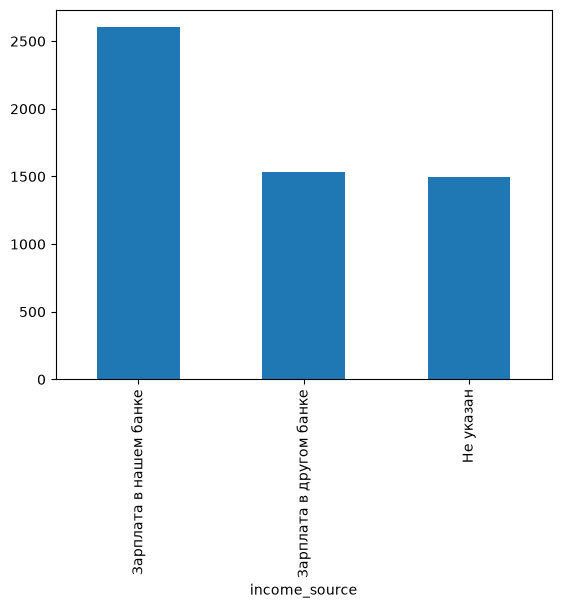

In [260]:
df_clients['income_source'].value_counts().plot.bar()

In [261]:
pd.crosstab(df_clients['income_source'], df_clients['card_type'])

card_type                Дебетовая  Кредитная  Премиальная
income_source                                             
Зарплата в другом банке       1039        312          183
Зарплата в нашем банке        1772        607          223
Не указан                     1084        295          119

### Доход

<Axes: >

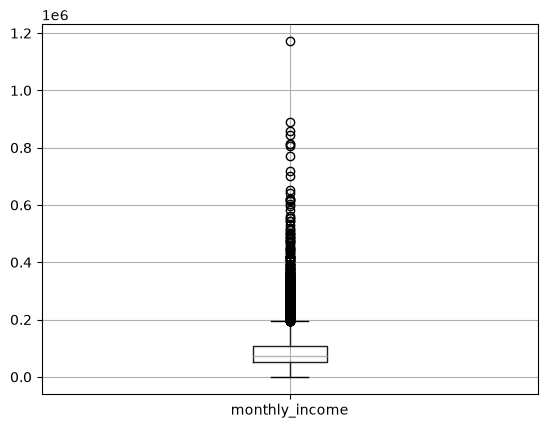

In [262]:
df_clients.boxplot(column='monthly_income')

<Axes: >

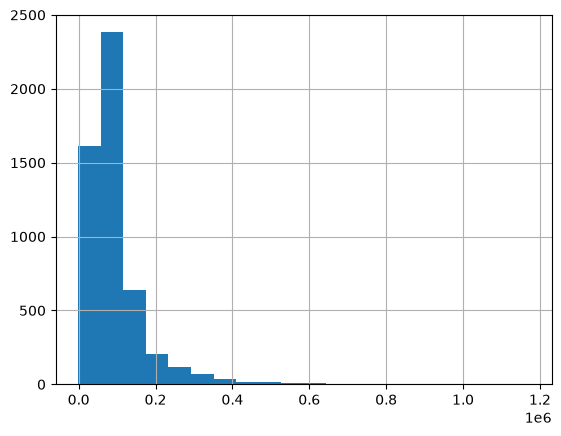

In [263]:
df_clients['monthly_income'].hist(bins = 20)

In [264]:
(df_clients['monthly_income'] > df_clients['monthly_income'].quantile(0.75)*1.5).sum()

np.int64(560)

In [265]:
df_clients[df_clients['monthly_income'] > 0].sort_values(by = 'monthly_income')

client_id birth_date gender             city   segment loyalty_tier  \
2161   C000141 1971-06-10      Ж           Казань  Массовый      Базовый   
5130   C000748 1988-08-04      Ж           Казань  Массовый      Серебро   
752    C000234 1974-10-21      М      Новосибирск  Массовый      Базовый   
476    C001353 1972-08-14      Ж  Санкт-Петербург  Массовый      Серебро   
1324   C005362 1984-10-05      Ж  Нижний Новгород  Массовый      Базовый   
...        ...        ...    ...              ...       ...          ...   
1982   C004081 1978-05-12      Ж           Казань   Private      Серебро   
3632   C001796 1966-06-24      Ж  Санкт-Петербург   Private      Платина   
3049   C002022 1977-11-22      Ж     Екатеринбург   Private      Платина   
2197   C000171 1968-04-24      Ж           Москва   Private      Платина   
2495   C004668 1974-04-01      М           Москва   Private       Золото   

        card_type registration_date card_open_date            income_source  \
2161    Дебетовая        2011-09-18     2016-10-25                Не указан   
5130    Дебетовая        2016-10-14     2020-12-07   Зарплата в нашем банке   
752     Дебетовая        2017-06-15     2017-10-15  Зарплата в другом банке   
476     Дебетовая        2019-03-12     2025-03-08   Зарплата в нашем банке   
1324    Кредитная        2018-03-14     2022-10-08                Не указан   
...           ...               ...            ...                      ...   
1982    Дебетовая        2018-09-17     2018-11-09                Не указан   
3632    Дебетовая        2018-11-16     2021-07-22  Зарплата в другом банке   
3049  Премиальная        2019-04-26     2022-02-02                Не указан   
2197    Кредитная        2018-03-29     2018-08-24  Зарплата в другом банке   
2495    Дебетовая        2022-11-04     2023-08-17  Зарплата в другом банке   

      monthly_income has_mobile_app app_last_login  satisfaction_score  \
2161            21.0             Да     2024-08-01                <NA>   
5130            23.1             Да     2024-11-01                <NA>   
752             30.4             Да     2024-03-01                   4   
476             30.4             Да     2025-03-01                   2   
1324            30.4            Нет            NaT                <NA>   
...              ...            ...            ...                 ...   
1982        813800.0             Да     2025-04-01                   1   
3632        843500.0            Нет            NaT                   2   
3049        857800.0            Нет            NaT                   5   
2197        890100.0             Да     2024-01-01                   2   
2495       1172000.0             Да     2024-06-01                <NA>   

      branch_code marketing_opt_in  
2161          878               Да  
5130          438               Да  
752           585               Да  
476           909              Нет  
1324          133               Да  
...           ...              ...  
1982          451               Да  
3632          432               Да  
3049          874               Да  
2197          552               Да  
2495          732              Нет  

[5076 rows x 16 columns]

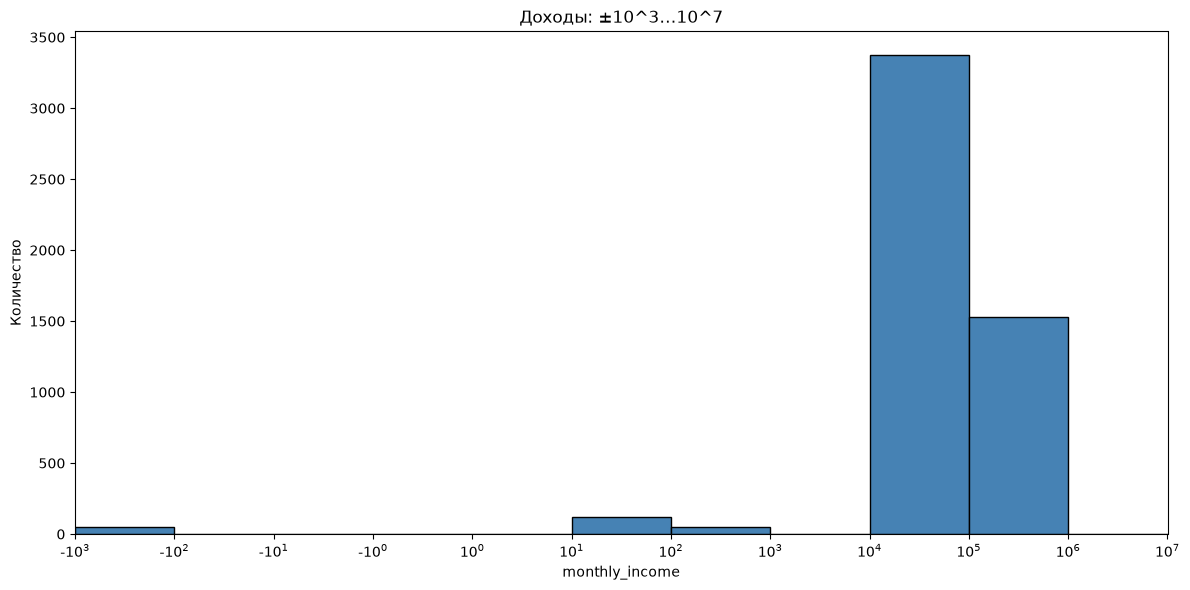

In [266]:
LIMITS = (-3, 7)

s = df_clients['monthly_income'].dropna()

neg_bins = -(10.0 ** np.arange(0, -LIMITS[0] + 1))[::-1]
pos_bins = 10.0 ** np.arange(0, LIMITS[1] + 1)
bins = np.concatenate([neg_bins, pos_bins])

counts, _ = np.histogram(s, bins=bins)

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(np.arange(len(counts)), counts, width=1.0, edgecolor='black', color='steelblue')

boundaries = np.arange(len(bins)) - 0.5
ax.set_xticks(boundaries)

ax.set_xticklabels([f"{'-' if x < 0 else ''}$10^{{{int(round(np.log10(abs(x))))}}}$" for x in bins])

ax.set_xlim(-0.5, len(counts) - 0.5)
ax.set_xlabel('monthly_income')
ax.set_ylabel('Количество')
ax.set_title(f'Доходы: ±10^{abs(LIMITS[0])}…10^{LIMITS[1]}')
plt.tight_layout()
plt.show()

In [267]:
income = df_clients['monthly_income']
low_mask = (income > 0) & (income < 1000)
high_mask = (income > 1000)
print(income[low_mask].mean())
print(income[low_mask].std())
print(income[high_mask].mean())
print(income[high_mask].std())

95.16176470588235
80.37686828588974
99193.29392580513
81008.21139759188


In [268]:

group_a = income[low_mask]*1000
group_b = income[high_mask]

# 2. Проводим тест
res = stats.ks_2samp(group_a, group_b)

# 3. Выводим результат
print(f"Размер группы A: {len(group_a)}")
print(f"Размер группы B: {len(group_b)}")
print(f"KS-статистика (D): {res.statistic:.4f}")
print(f"p-value: {res.pvalue:.4e}")

# 4. Интерпретация
alpha = 0.05
if res.pvalue < alpha:
    print("Вывод: Распределения статистически значимо РАЗЛИЧАЮТСЯ (отвергаем H0).")
else:
    print("Вывод: Нет оснований полагать, что распределения различаются (принимаем H0).")

Размер группы A: 170
Размер группы B: 4906
KS-статистика (D): 0.0581
p-value: 6.1332e-01
Вывод: Нет оснований полагать, что распределения различаются (принимаем H0).


In [269]:
print("все значения в low это десятичные с одной цифрой после запятой:", (income[low_mask].round(1) == income[low_mask]).all())


все значения в low это десятичные с одной цифрой после запятой: True


In [270]:
print("все значения в high закачиваются на два нулся:", (income[high_mask] % 100 == 0).all())

все значения в high закачиваются на два нулся: True


In [271]:
s = df_clients['monthly_income']

# --- 1. Где разрыв в распределении? ---
pos = np.sort(s[s > 0].values)
low, high = pos[pos < 1000], pos[pos >= 1000]

gaps = np.diff(np.log10(pos))
i = gaps.argmax()          # самый большой скачок в порядке величины

print(f'Максимальный разрыв: {pos[i]:.1f} -> {pos[i + 1]:.1f}  '
      f'(в {pos[i + 1] / pos[i]:.0f} раз), значений в нём: 0')
print(f'Кластер <1000  : n={low.size:3d}, диапазон {low.min():.1f} ... {low.max():.1f}')
print(f'Кластер >=1000 : n={high.size:4d}, диапазон {high.min():.0f} ... {high.max():.0f}')

neg = s[s < 0]
print(f'Отрицательные  : n={neg.size}, уникальных значений {neg.nunique()} -> {sorted(neg.unique())}')

# --- 2. Похожа ли "мелочь" на основную массу, сжатую в 1000 раз? ---
q = [.05, .25, .5, .75, .95]
cmp = pd.DataFrame({
    'low (<1000)':   pd.Series(low),
    'low x 1000':    pd.Series(low * 1000),
    'high (>=1000)': pd.Series(high),
}).quantile(q).round(0).astype(int)
print('\nКвантили, руб.:')
print(cmp)

Максимальный разрыв: 580.7 -> 15100.0  (в 26 раз), значений в нём: 0
Кластер <1000  : n=170, диапазон 21.0 ... 580.7
Кластер >=1000 : n=4906, диапазон 15100 ... 1172000
Отрицательные  : n=47, уникальных значений 1 -> [np.float64(-999.0)]

Квантили, руб.:
      low (<1000)  low x 1000  high (>=1000)
0.05           35       35295          35800
0.25           53       52550          55100
0.50           74       74250          75850
0.75          104      104250         111800
0.95          226      225615         253300


In [272]:
income = df_clients['monthly_income']
low_mask = (income > 0) & (income < 1000)
high_mask = (income > 1000)

df_clients.loc[low_mask, 'monthly_income'] *=1000
df_clients.loc[income < 0, 'monthly_income'] = np.nan

In [273]:
desc = df_clients['monthly_income'].describe().round(2)
desc.loc['median'] = df_clients['monthly_income'].median()
desc

count        5076.00
mean        99058.27
std         80982.53
min         15100.00
25%         55075.00
50%         75800.00
75%        111525.00
max       1172000.00
median      75800.00
Name: monthly_income, dtype: float64

<Axes: >

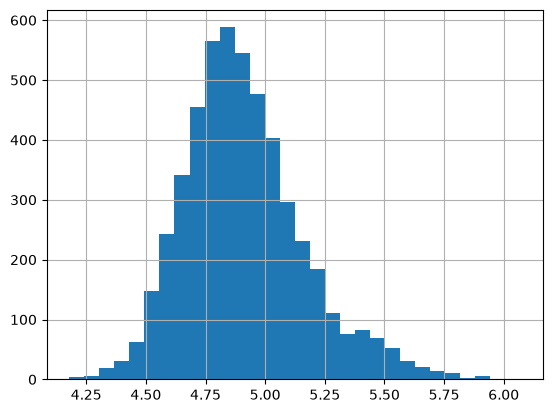

In [274]:
np.log10(df_clients['monthly_income']).hist(bins = 30)

### branch code

In [275]:
df_clients.groupby('branch_code')['city'].unique()

branch_code
100      [Нижний Новгород, Москва, Екатеринбург, Казань]
101                    [Санкт-Петербург, Москва, Казань]
102         [Екатеринбург, Новосибирск, Санкт-Петербург]
103    [Москва, Нижний Новгород, Екатеринбург, Санкт-...
104                                             [Москва]
                             ...                        
935                            [Нижний Новгород, Москва]
936      [Санкт-Петербург, Москва, Казань, Екатеринбург]
937    [Москва, Санкт-Петербург, Нижний Новгород, Ека...
938                    [Казань, Москва, Санкт-Петербург]
939    [Санкт-Петербург, Новосибирск, Москва, Екатери...
Name: city, Length: 840, dtype: object

In [276]:
print(df_clients['branch_code'].unique())

[905 635 872 443 598 322 196 920 600 544 469 581 751 363 356 235 672 241
 586 349 762 540 354 559 887 665 207 682 351 115 314 822 523 140 365 859
 869 666 491 805 370 890 189 547 678 786 519 418 858 227 485 273 280 412
 844 840 277 767 562 731 502 851 334 337 199 662 914 694 908 182 722 282
 433 143 526 752 674 922 612 246 797 604 409 131 541 939 215 888 755 743
 554 439 117 856 441 710 637 904 719 400 171 582 408 135 901 248 473 552
 814 278 156 394 141 879 130 180 651 667 375 331 735 175 792 862 508 620
 327 618 616 158 758 307 317 464 330 444 257 253 734 392 686 773 453 779
 447 654 700 323 739 195 531 583 152 137 316 653 895 442 560 510 463 484
 395 372 405 163 549 849 728 455 588 820 450 225 599 294 222 825 188 428
 313 403 487 572 312 711 737 533 192 236 376 603 274 170 118 932 237 100
 332 615 133 415 223 622 357 629 276 308 812 817 726 687 377 387 798 617
 461 181 154 435 702 848 138 627 293 221 793 311 492 383 928 803 460 806
 671 902 701 723 213 589 880 513 573 730 759 697 69

In [277]:
df_clients = df_clients.drop(['branch_code'], axis = 1)

### Мобильное приложение

<Axes: xlabel='has_mobile_app'>

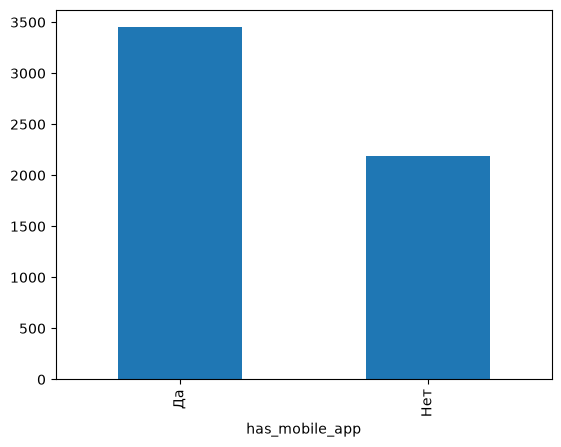

In [278]:
df_clients['has_mobile_app'].value_counts().plot.bar()

<Axes: >

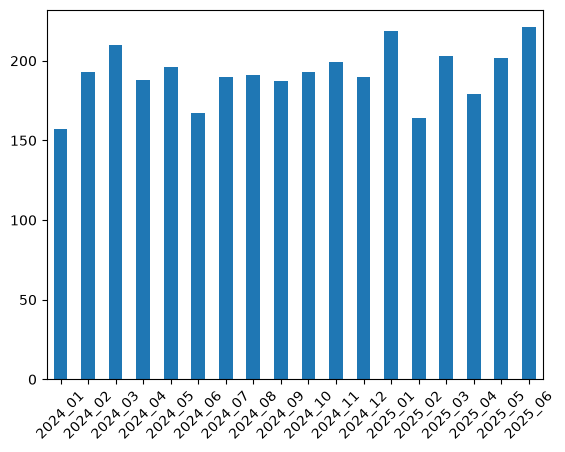

In [279]:
app_2024 = df_clients.loc[df_clients['app_last_login'].dt.year == 2024, 'app_last_login']
app_2025 = df_clients.loc[df_clients['app_last_login'].dt.year == 2025, 'app_last_login']

cnt_2024 = app_2024.dt.month.value_counts()
cnt_2025 = app_2025.dt.month.value_counts()
cnt_2024.index = [f"2024_{i:02d}" for i in cnt_2024.index]
cnt_2025.index = [f"2025_{i:02d}" for i in cnt_2025.index]

pd.concat([cnt_2024, cnt_2025], axis=0).sort_index().plot.bar(rot = 45)

In [280]:
(df_clients['app_last_login'].isna() == (df_clients['has_mobile_app'] == 'Нет')).all()

np.True_

### Рейтинг

<Axes: xlabel='satisfaction_score'>

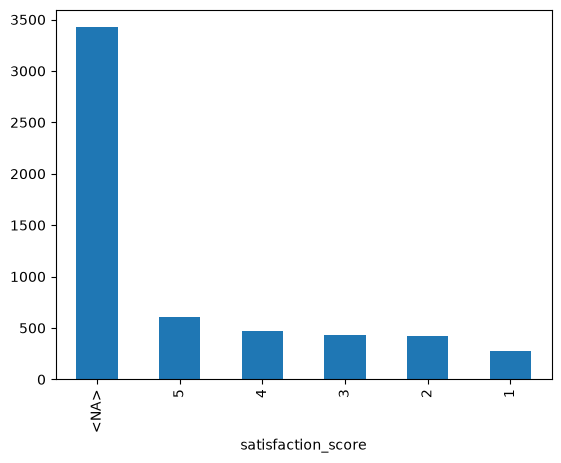

In [281]:
df_clients['satisfaction_score'].value_counts(dropna=False).plot.bar()

### Маркетинговое взаимодействие


<Axes: xlabel='marketing_opt_in'>

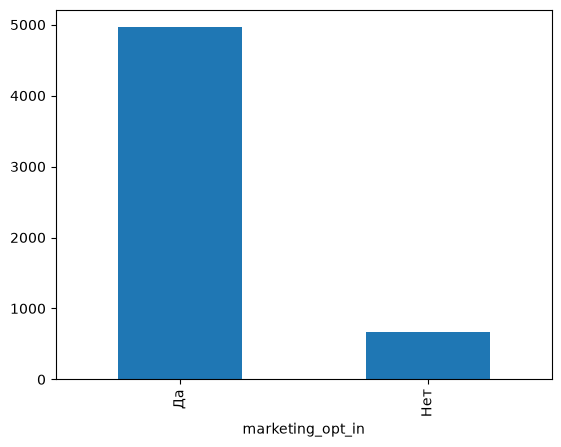

In [282]:

df_clients['marketing_opt_in'].value_counts(dropna=False).plot.bar()

<Axes: xlabel='birth_date'>

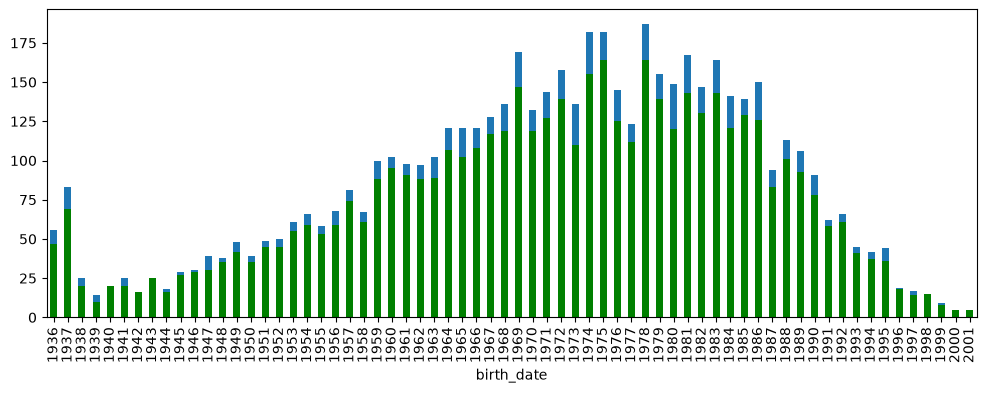

In [283]:
df_clients['birth_date'].dt.year.value_counts().sort_index().plot.bar(figsize=(12, 4))
mark_opt = df_clients['marketing_opt_in'] == "Да"
df_clients[mark_opt]['birth_date'].dt.year.value_counts().sort_index().plot.bar(figsize=(12, 4), color = "green")

## Транзакции


In [284]:
print(df_transactions.shape)
df_transactions.nunique()


(623776, 9)


txn_id          623776
client_id         5985
txn_datetime    568456
amount          323082
currency             3
category            12
mcc_code             9
channel              4
status               3
dtype: int64

### Категории и коды

In [285]:
df_transactions.index = df_transactions['txn_id']
df_transactions = df_transactions.drop(['txn_id'], axis = 1)

In [286]:
df_transactions[['category', 'mcc_code']].drop_duplicates()

category  mcc_code
txn_id                            
990163    Одежда и обувь      5651
990199          Продукты      5411
990046         Транспорт      4111
100002               АЗС      5541
100004    Кафе/рестораны      5812
...                  ...       ...
311639  Связь и Интернет      5912
311849    Кафе/рестораны      5411
313777  Связь и Интернет      7832
317329  Связь и Интернет      4111
365776  Связь и интернет      5541

[108 rows x 2 columns]

In [287]:
df_transactions['category'].unique().tolist()

['Одежда и обувь',
 'Продукты',
 'Транспорт',
 'АЗС',
 'Кафе/рестораны',
 'кафе и рестораны',
 'Развлечения и досуг',
 'Онлайн-сервисы',
 'Кафе и рестораны',
 'Связь и интернет',
 'Связь и Интернет',
 'Аптеки']

In [288]:
caffee_mask = df_transactions['category'].isin(['Кафе/рестораны', 'кафе и рестораны'])
df_transactions.loc[caffee_mask, 'category'] = 'Кафе и рестораны'

inet_mask = df_transactions['category'] == 'Связь и Интернет'
df_transactions.loc[inet_mask, 'category'] = 'Связь и интернет'
df_transactions['category'] = df_transactions['category'].cat.remove_unused_categories()

In [289]:
df_transactions['category'].unique()

['Одежда и обувь', 'Продукты', 'Транспорт', 'АЗС', 'Кафе и рестораны', 'Развлечения и досуг', 'Онлайн-сервисы', 'Связь и интернет', 'Аптеки']
Categories (9, str): ['АЗС', 'Аптеки', 'Кафе и рестораны', 'Одежда и обувь', ..., 'Продукты', 'Развлечения и досуг', 'Связь и интернет', 'Транспорт']

In [290]:
df_transactions[['category', 'mcc_code']].drop_duplicates()

category  mcc_code
txn_id                               
990163       Одежда и обувь      5651
990199             Продукты      5411
990046            Транспорт      4111
100002                  АЗС      5541
100004     Кафе и рестораны      5812
...                     ...       ...
198413  Развлечения и досуг      4111
200689  Развлечения и досуг      5815
217547       Онлайн-сервисы      4814
244743               Аптеки      5815
264681  Развлечения и досуг      5812

[81 rows x 2 columns]

In [291]:
df_transactions.groupby('category')['mcc_code'].unique().apply(sorted)

category
АЗС                    [4111, 4814, 5411, 5541, 5651, 5812, 5815, 591...
Аптеки                 [4111, 4814, 5411, 5541, 5651, 5812, 5815, 591...
Кафе и рестораны       [4111, 4814, 5411, 5541, 5651, 5812, 5815, 591...
Одежда и обувь         [4111, 4814, 5411, 5541, 5651, 5812, 5815, 591...
Онлайн-сервисы         [4111, 4814, 5411, 5541, 5651, 5812, 5815, 591...
Продукты               [4111, 4814, 5411, 5541, 5651, 5812, 5815, 591...
Развлечения и досуг    [4111, 4814, 5411, 5541, 5651, 5812, 5815, 591...
Связь и интернет       [4111, 4814, 5411, 5541, 5651, 5812, 5815, 591...
Транспорт              [4111, 4814, 5411, 5541, 5651, 5812, 5815, 591...
Name: mcc_code, dtype: object

In [292]:
pd.crosstab(df_transactions['category'],df_transactions['mcc_code'])

mcc_code              4111   4814    5411   5541   5651   5812   5815   5912  \
category                                                                       
АЗС                     13     16      20  57716     20     25     29     20   
Аптеки                  23     12      17     19     13     21      8  44816   
Кафе и рестораны        31     31      27     27     36  80963     24     32   
Одежда и обувь          26     25      30     18  64644     17     26     21   
Онлайн-сервисы          12     14      17     18     14     15  43399     16   
Продукты                48     64  163683     53     47     62     48     50   
Развлечения и досуг     20      7      19     18     18     12     26     15   
Связь и интернет        13  48330      17     15     10     18     20     14   
Транспорт            71068     33      15     30     16     21     26     27   

mcc_code              7832  
category                    
АЗС                     21  
Аптеки                  14  
Кафе и рестораны        35  
Одежда и обувь          18  
Онлайн-сервисы          15  
Продукты                58  
Развлечения и досуг  47454  
Связь и интернет         9  
Транспорт               18

In [293]:
df_transactions = df_transactions.drop(['mcc_code'], axis =1)

### Channel

<Axes: xlabel='channel'>

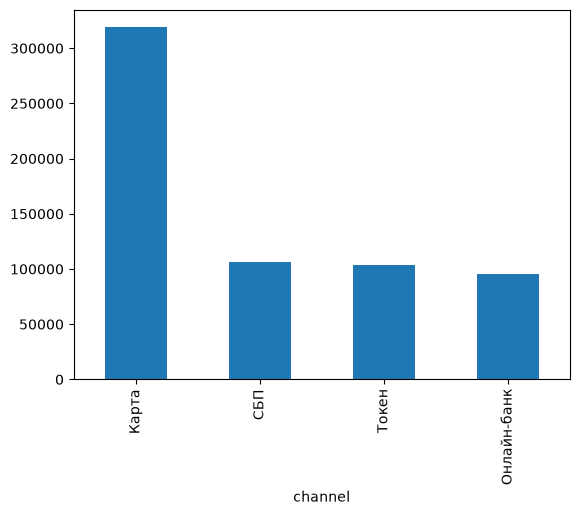

In [294]:
df_transactions['channel'].value_counts().plot.bar()

In [295]:
card_transactions_mask = df_transactions['channel'] == 'Карта'
card_transactions = df_transactions[card_transactions_mask]
other_transactions = df_transactions[~card_transactions_mask]

### Время транзакции

<Axes: xlabel='txn_datetime'>

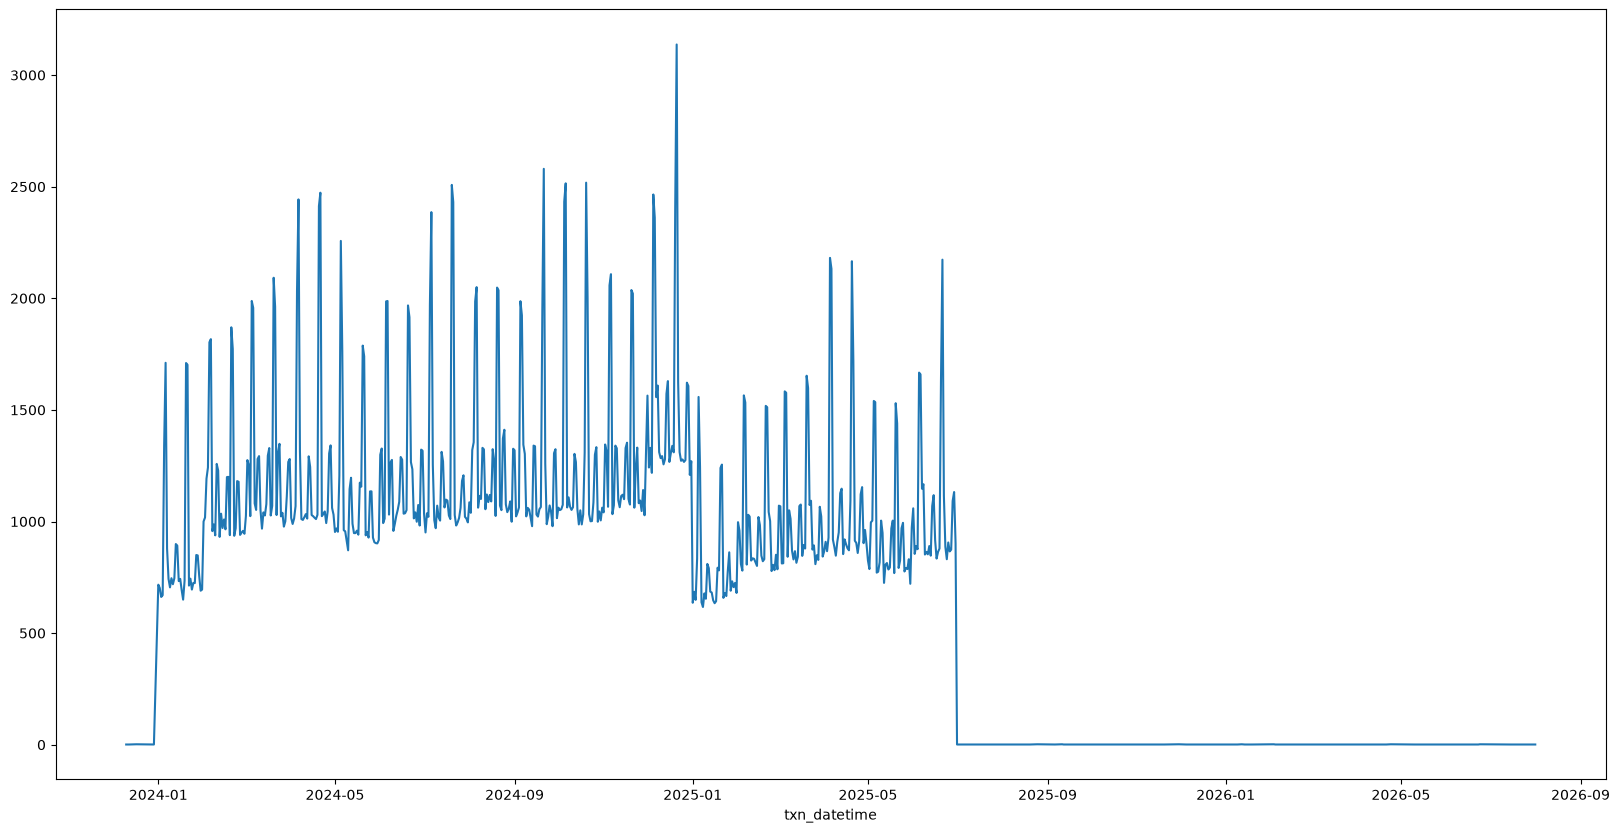

In [296]:
df_transactions['txn_datetime'].dt.date.value_counts().sort_index().plot(figsize = (20, 10))

In [297]:
df_transactions['txn_datetime'].dt.date.value_counts().sort_index(ascending=False)

txn_datetime
2026-08-01    1
2026-07-23    1
2026-07-15    1
2026-07-09    1
2026-06-24    2
             ..
2023-12-29    1
2023-12-28    1
2023-12-17    2
2023-12-12    1
2023-12-10    1
Name: count, Length: 623, dtype: int64

In [298]:
tnx_date = df_transactions['txn_datetime'].dt.date
out_of_date_mask = ((tnx_date < datetime.date(2024, 1, 1)) | ((tnx_date > datetime.date(2025, 7, 1))))
out_of_date_mask.sum()

np.int64(84)

In [299]:
df_transactions.loc[out_of_date_mask, 'txn_datetime'].value_counts().sort_values(ascending = False)

txn_datetime
2023-12-10 00:00:00    1
2023-12-12 12:19:56    1
2023-12-17 13:59:08    1
2023-12-17 14:36:01    1
2023-12-28 06:54:01    1
                      ..
2026-06-24 16:19:11    1
2026-07-09 09:25:04    1
2026-07-15 10:58:41    1
2026-07-23 10:34:51    1
2026-08-01 14:07:43    1
Name: count, Length: 84, dtype: int64

In [300]:
df_transactions[out_of_date_mask]

client_id        txn_datetime   amount currency             category  \
txn_id                                                                        
990163   C001976 2023-12-10 00:00:00  4638.38      RUB       Одежда и обувь   
990199   C004215 2023-12-12 12:19:56   507.22      RUB             Продукты   
990072   C004029 2023-12-17 13:59:08   902.94      RUB             Продукты   
990033   C001144 2023-12-17 14:36:01   247.73      RUB             Продукты   
990046   C001369 2023-12-28 06:54:01   135.79      RUB            Транспорт   
...          ...                 ...      ...      ...                  ...   
990152   C001912 2026-06-24 16:19:11  1060.70      RUB  Развлечения и досуг   
990194   C001002 2026-07-09 09:25:04  3045.29      RUB       Одежда и обувь   
990206   C001650 2026-07-15 10:58:41  9107.46      RUB       Одежда и обувь   
990054   C005540 2026-07-23 10:34:51   813.12      RUB                  АЗС   
990138   C004334 2026-08-01 14:07:43  1641.76      RUB  Развлечения и досуг   

       channel     status  
txn_id                     
990163   Карта    успешно  
990199   Карта    успешно  
990072   Карта    успешно  
990033   Карта    успешно  
990046   Карта    успешно  
...        ...        ...  
990152   Карта    успешно  
990194   Токен    успешно  
990206   Карта    успешно  
990054   Карта  отклонено  
990138   Токен    успешно  

[84 rows x 7 columns]

In [301]:
df_transactions = df_transactions[~out_of_date_mask]

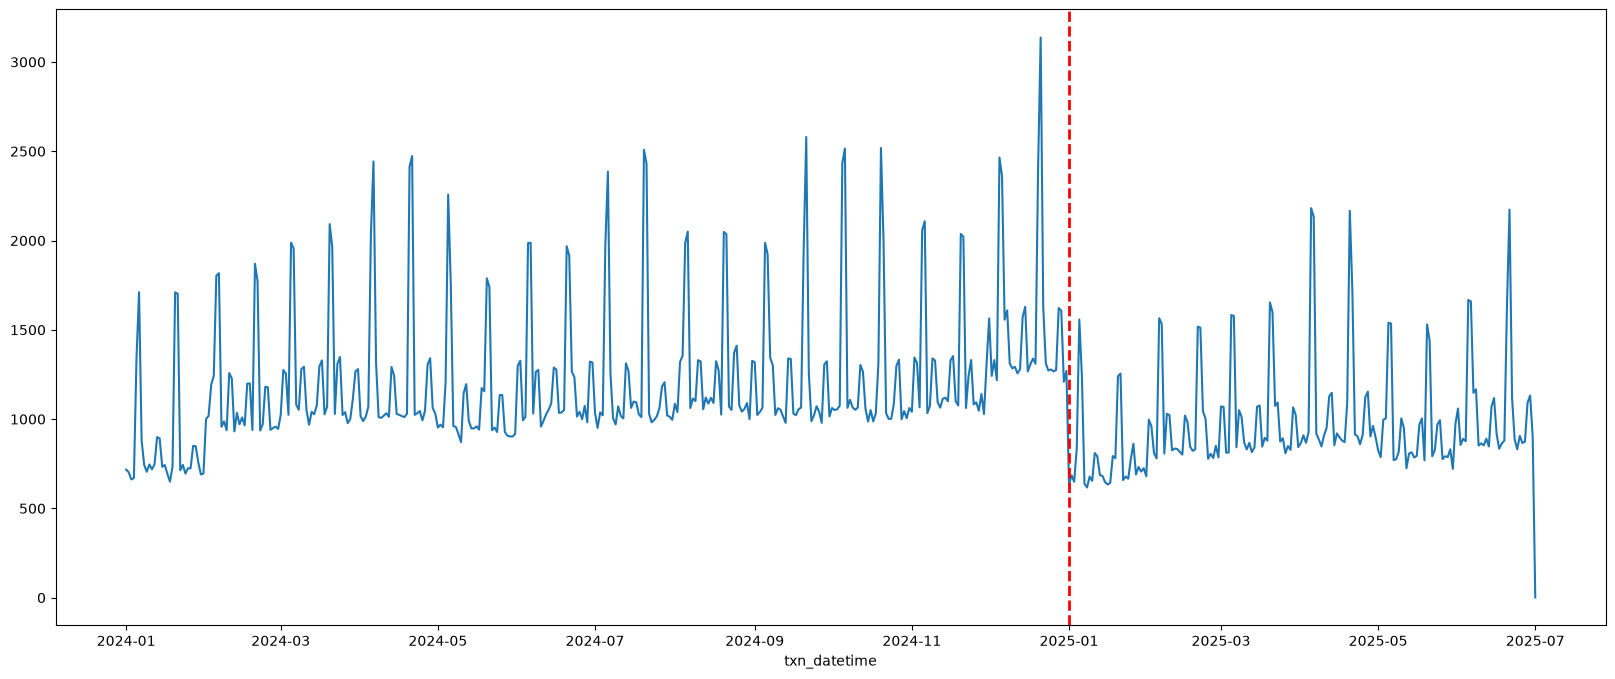

In [302]:
df_transactions['txn_datetime'].dt.date.value_counts().sort_index().plot(figsize = (20, 8))
plt.axvline(x='2025-01-01', color = 'red', linestyle='--',  linewidth=2,)

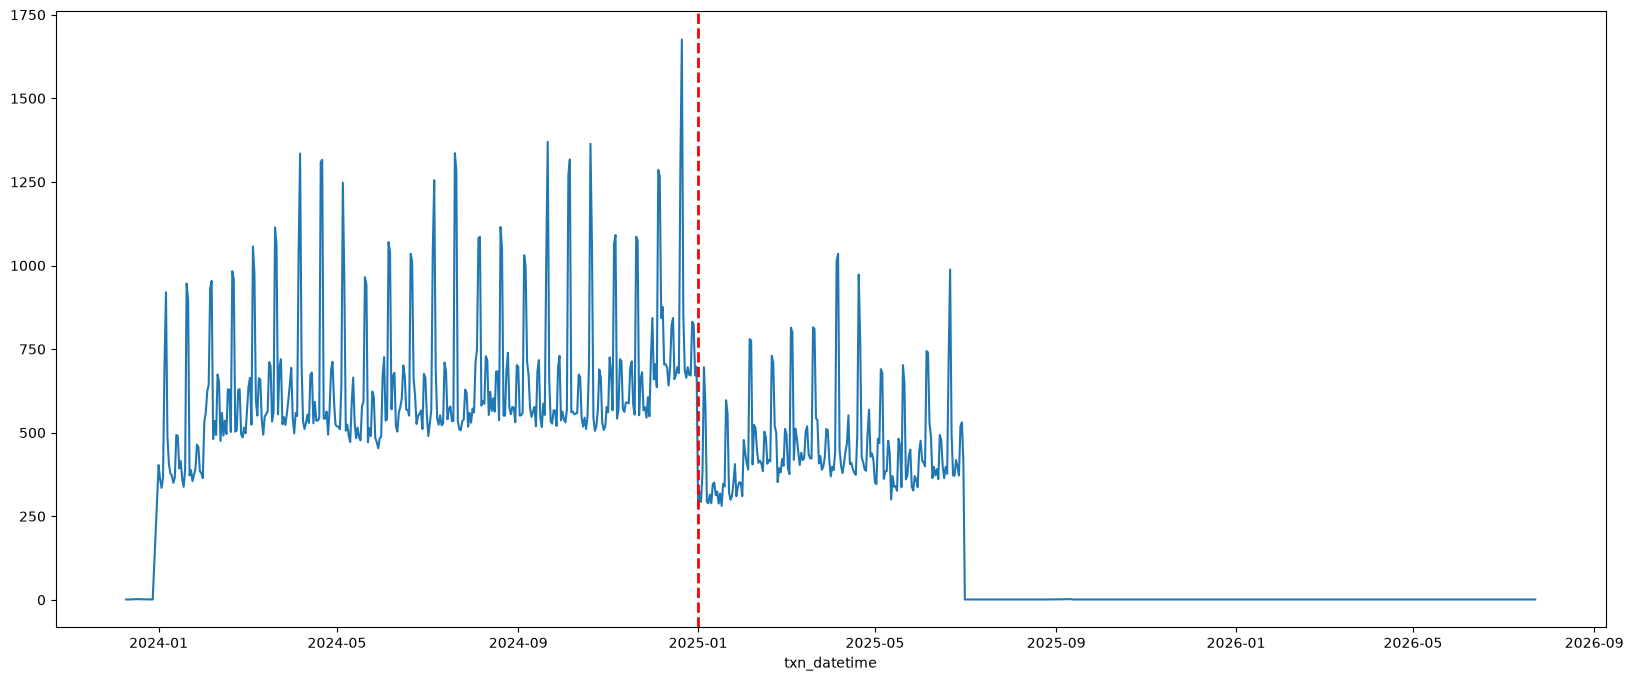

In [303]:
card_transactions['txn_datetime'].dt.date.value_counts().sort_index().plot(figsize = (20, 8))
plt.axvline(x='2025-01-01', color = 'red', linestyle='--',  linewidth=2,)

In [304]:
card_transactions['txn_datetime'].dt.date.value_counts().corr(other_transactions['txn_datetime'].dt.date.value_counts())

np.float64(0.9347953420599604)

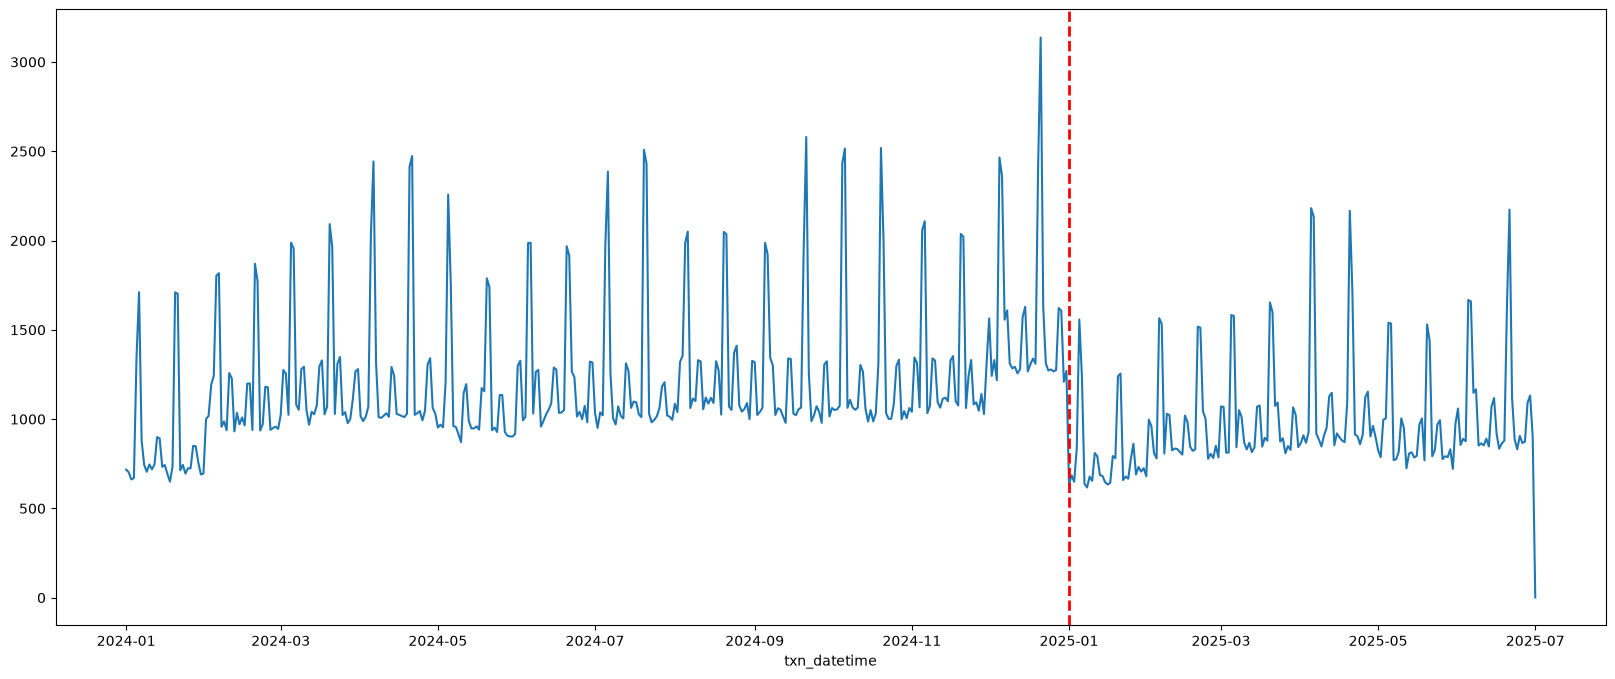

In [305]:
df_transactions['txn_datetime'].dt.date.value_counts().sort_index().plot(figsize = (20, 8))
plt.axvline(x='2025-01-01', color = 'red', linestyle='--',  linewidth=2,)

<Axes: xlabel='txn_datetime'>

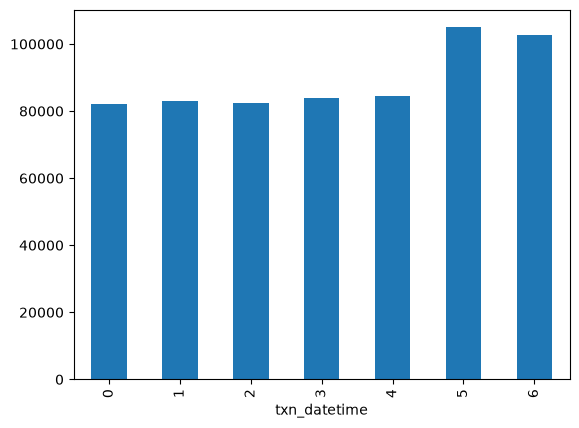

In [306]:
df_transactions['txn_datetime'].dt.day_of_week.value_counts().sort_index().plot.bar()

<Axes: xlabel='txn_datetime'>

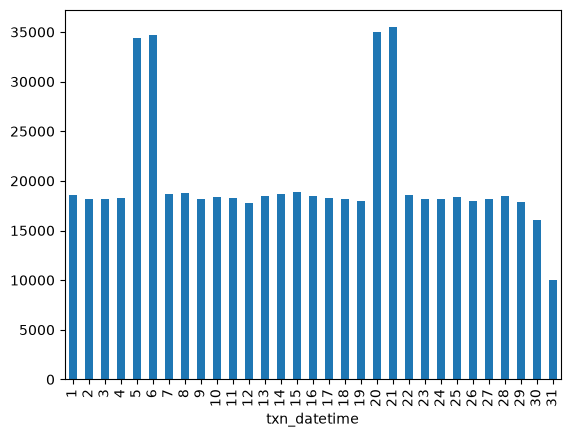

In [307]:
df_transactions['txn_datetime'].dt.day.value_counts().sort_index().plot.bar()

In [308]:
tnx_by_client = df_transactions.groupby(['client_id'])['txn_datetime'].count()
print(f'mean {tnx_by_client.mean()}')
print(f'std {tnx_by_client.std()}')
tnx_by_client.value_counts().sort_index()

mean 104.20918964076859
std 77.04489464724342


txn_datetime
1      21
2      37
3      39
4      46
5      33
       ..
535     1
563     1
570     1
583     1
634     1
Name: count, Length: 392, dtype: int64

<Axes: xlabel='txn_datetime'>

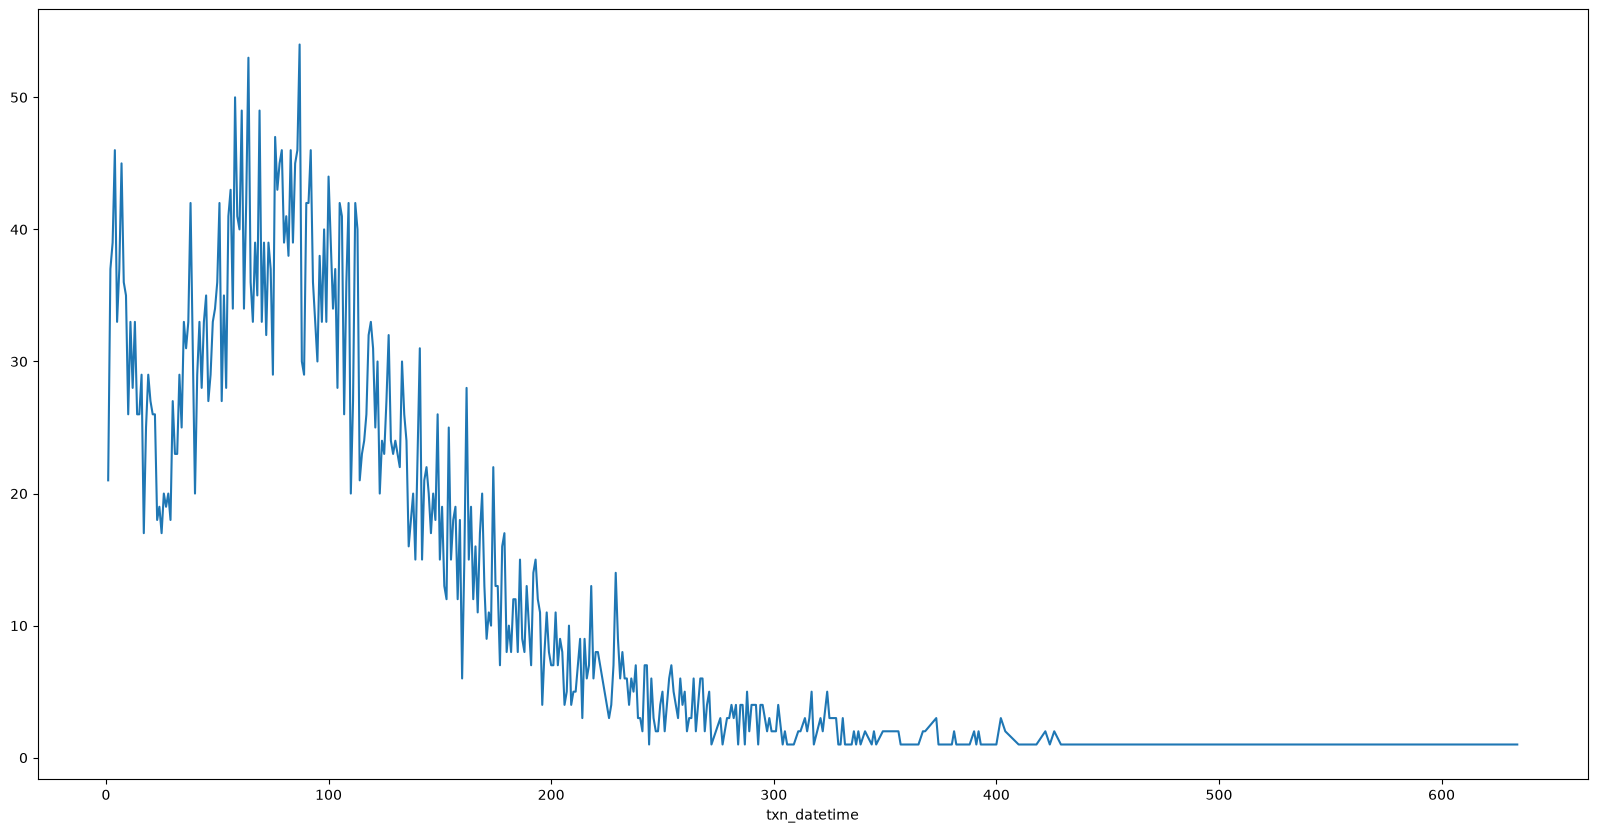

In [309]:
tnx_by_client.value_counts().sort_index().plot(figsize = (20, 10))

In [310]:
### Денежные траты

<Axes: xlabel='currency'>

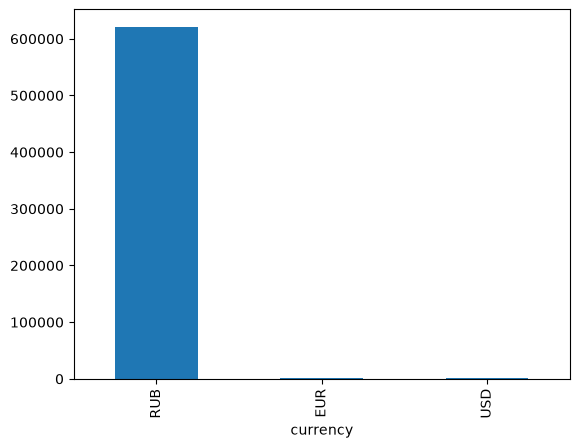

In [311]:
df_transactions['currency'].value_counts().plot.bar()

In [312]:
not_rub_mask = ~(df_transactions['currency'] == 'RUB')
print('транзакций не в рублхях', not_rub_mask.sum())
print('клинтов с такими транзакциями', df_transactions.loc[not_rub_mask, 'client_id'].unique().count())
clients_with_curr = df_transactions.loc[not_rub_mask, 'client_id'].unique()
all_tnx_clients_with_curr = df_transactions[df_transactions['client_id'].isin(clients_with_curr)]['client_id']
(df_transactions.loc[not_rub_mask, 'client_id'].value_counts() / all_tnx_clients_with_curr.value_counts()).sort_values(ascending = False)

транзакций не в рублхях 2618
клинтов с такими транзакциями 1937


client_id
C004382         0.5
C001712    0.333333
C000673    0.333333
C005349    0.333333
C003891         0.2
             ...   
C000926    0.001946
C003000    0.001916
C003478    0.001869
C000296    0.001754
C001687    0.001577
Name: count, Length: 1937, dtype: Float64

/home/cati0n/DATA_CAMP/1 лаба/Rudman_Ivan_Lab1/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:438: RuntimeWarning: invalid value encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


<Axes: ylabel='Frequency'>

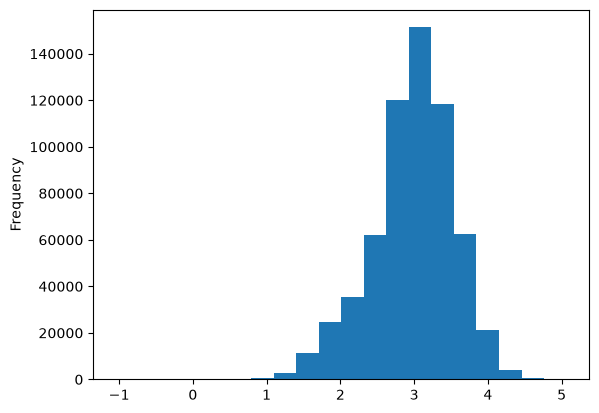

In [313]:

np.log10(df_transactions['amount']).plot.hist(bins=20)

In [314]:
exchange_rates = {
    2024: {
        "USD": {
            1: 89.29, 2: 91.87, 3: 92.37, 4: 91.78,
            5: 89.79, 6: 85.75, 7: 86.33, 8: 91.19,
            9: 92.71, 10: 97.05, 11: 107.74, 12: 101.68
        },
        "EUR": {
            1: 96.79, 2: 99.45, 3: 99.53, 4: 98.03,
            5: 97.13, 6: 92.42, 7: 93.29, 8: 100.76,
            9: 103.47, 10: 105.22, 11: 114.31, 12: 106.10
        }
    },
    2025: {
        "USD": {
            1: 98.01, 2: 87.70, 3: 83.68, 4: 81.56,
            5: 78.62, 6: 78.47, 7: 81.83
        },
        "EUR": {
            1: 102.78, 2: 92.04, 3: 89.66, 4: 93.17,
            5: 89.25, 6: 92.28, 7: 94.95
        }
    }
}

def curr_amount(row):
    year = row['txn_datetime'].year
    month = row['txn_datetime'].month
    match row['currency']:
        case 'USD':
            row['amount'] *= exchange_rates[year]['USD'][month] 
        case 'EUR':
            row['amount'] *= exchange_rates[year]['EUR'][month] 
    return row
            
df_transactions = df_transactions.apply(curr_amount, axis = 1)

In [315]:
df_transactions.groupby(['client_id'])['amount'].agg(['count', 'sum', 'min', 'max', 'mean', 'median']).sort_values('count')

count           sum        min       max         mean    median
client_id                                                                 
C002590        1  3.198100e+02   319.8100    319.81   319.810000   319.810
C002608        1  2.479890e+03  2479.8900   2479.89  2479.890000  2479.890
C003947        1  1.368700e+03  1368.7000   1368.70  1368.700000  1368.700
C005065        1  1.876470e+03  1876.4700   1876.47  1876.470000  1876.470
C005070        1  2.817000e+02   281.7000    281.70   281.700000   281.700
...          ...           ...        ...       ...          ...       ...
C003478      535  1.149538e+06 -3890.8000  18332.82  2148.668893  1285.720
C003062      563  1.332695e+06 -2791.2100  25034.48  2367.131197  1522.550
C000296      570  6.578719e+05 -2752.7900  16167.32  1154.161155   737.390
C001160      583  6.683131e+05 -3901.4003  13886.76  1146.334667   698.890
C001687      634  2.547460e+06 -1070.9800  52896.42  4018.075308  2462.635

[5985 rows x 6 columns]

<Axes: >

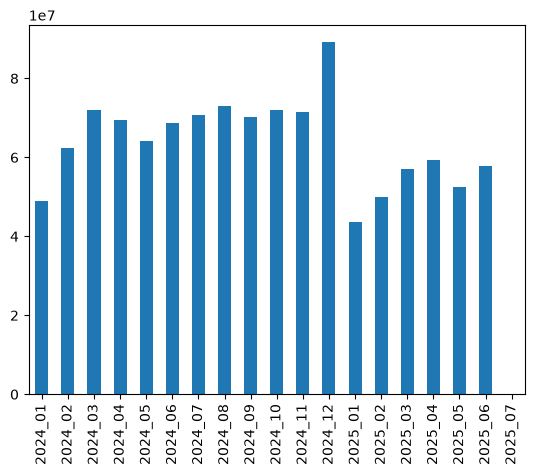

In [316]:
df_2024 = df_transactions[df_transactions['txn_datetime'].dt.year == 2024]
df_2025 = df_transactions[df_transactions['txn_datetime'].dt.year == 2025]

sum_2024 = df_transactions.groupby(df_2024['txn_datetime'].dt.month)['amount'].sum().sort_index()
sum_2025 = df_transactions.groupby(df_2025['txn_datetime'].dt.month)['amount'].sum().sort_index()

sum_2024.index = [f'2024_{int(i):02d}' for i in sum_2024.index]
sum_2025.index = [f'2025_{int(i):02d}' for i in sum_2025.index]

sum_all = pd.concat([sum_2024, sum_2025], axis=0)
sum_all.plot.bar()

<Axes: >

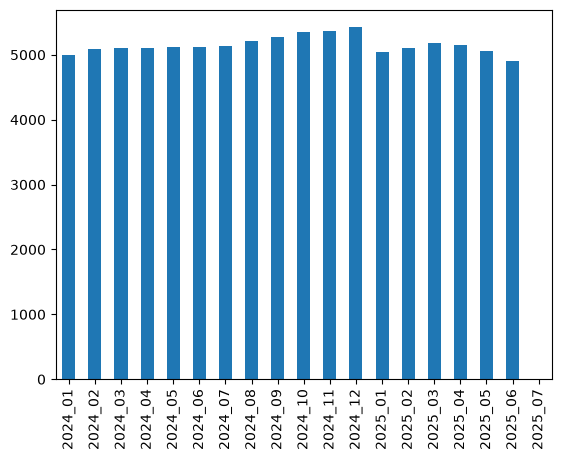

In [317]:
df_2024 = df_transactions[df_transactions['txn_datetime'].dt.year == 2024]
df_2025 = df_transactions[df_transactions['txn_datetime'].dt.year == 2025]

sum_2024 = df_transactions.groupby(df_2024['txn_datetime'].dt.month)['client_id'].agg(lambda x: x.unique().count()).sort_index()
sum_2025 = df_transactions.groupby(df_2025['txn_datetime'].dt.month)['client_id'].agg(lambda x: x.unique().count()).sort_index()

sum_2024.index = [f'2024_{int(i):02d}' for i in sum_2024.index]
sum_2025.index = [f'2025_{int(i):02d}' for i in sum_2025.index]

sum_all = pd.concat([sum_2024, sum_2025], axis=0)
sum_all.plot.bar()

In [318]:
sum_all.to_frame().T

2024_01  2024_02  2024_03  2024_04  2024_05  2024_06  2024_07  \
client_id     4996     5086     5112     5102     5113     5114     5135   

           2024_08  2024_09  2024_10  2024_11  2024_12  2025_01  2025_02  \
client_id     5207     5270     5350     5372     5424     5041     5107   

           2025_03  2025_04  2025_05  2025_06  2025_07  
client_id     5176     5147     5063     4903        1

In [ ]:
###

### Клиенты

#### Метрика активности

Поля «активность» в данных нет — она определяется здесь.

**Что считаем операцией.** Успешная операция клиента из справочника в окне
2024-01-01 … 2025-06-30. Отклонённые операции не состоялись, возвраты отменяют
уже учтённую покупку, поэтому в метрику идут только `status = успешно`.
Суммы приведены к рублям в блоке «Денежные траты».

**Основная метрика — число успешных операций в расчёте на месяц:**

    rate = (число успешных операций в окне) / (число месяцев в окне)    12 для 2024, 6 для 2025 H1

Почему частота, а не сумма:

- окна лежат в разных годах — сумма тянет за собой инфляцию и курс;
- сумма ломается от одного крупного платежа, частота — нет;
- частота раскладывается по каналу и категории, то есть сразу отвечает на
  «за счёт чего упала активность».

**Контрольные метрики:** расход в месяц (`spend_rate`) и доля активных месяцев
(`active_share`). Единый «индекс активности» не строю: его нечем защищать,
а оценивается обоснование, а не формула.

**Сравнение окон.** Кроме «2024 целиком против 2025 H1» считаю like-for-like
«2024 H1 против 2025 H1» — иначе сезонность и декабрьский пик 2024 читаются
как падение.

**Чего метрика не видит:** падение суммы при той же частоте; инфляцию; траты
вне банка (уход к конкуренту выглядит как снижение активности); простой внутри
месяца; смену канала при сохранении частоты.

In [197]:
# ===== 1. Что считаем операцией для метрики активности =====
# Только успешные операции клиентов из справочника внутри окна 2024-01-01 .. 2025-06-30.
# Суммы уже приведены к рублям в блоке «Денежные траты».
WINDOW_START, WINDOW_END = pd.Timestamp('2024-01-01'), pd.Timestamp('2025-06-30')
BASE_MONTHS, EVAL_MONTHS = 12, 6
MIN_BASE_OPS = 6   # минимальная база: иначе «падение на 100%» считается от двух операций

df_act = df_transactions.loc[
    (df_transactions['status'] == 'успешно')
    & df_transactions['txn_datetime'].between(WINDOW_START, WINDOW_END)
    & df_transactions['client_id'].isin(df_clients['client_id'])
].copy()

df_act['month'] = df_act['txn_datetime'].dt.to_period('M')
df_act['period'] = np.where(df_act['month'] <= pd.Period('2024-12', 'M'), '2024', '2025 H1')
df_act['half_2024'] = df_act['month'] <= pd.Period('2024-06', 'M')
df_act['is_digital'] = df_act['channel'] != 'Карта'

print(f'операций в метрике: {len(df_act):,} из {len(df_transactions):,}')
print(f'клиентов: {df_act["client_id"].nunique():,} из {df_clients["client_id"].nunique():,}')
display(
    df_act.groupby('period', observed=True).agg(
        операций=('amount', 'size'),
        клиентов=('client_id', 'nunique'),
        месяцев=('month', 'nunique'),
        сумма_млн_руб=('amount', lambda s: s.sum() / 1e6),
    ).round(1)
)


операций в метрике: 573,251 из 623,692
клиентов: 5,634 из 5,634


операций  клиентов  месяцев  сумма_млн_руб
period                                             
2024       405680      5259       12          762.7
2025 H1    167571      5625        6          306.9

In [198]:
# ===== 2. Метрики активности в разрезе клиента и окна =====
def activity_stats(sub, suffix):
    """Агрегаты по клиенту внутри одного окна."""
    g = sub.groupby('client_id', observed=True)
    return pd.DataFrame({
        'ops': g.size(),                        # успешных операций в окне
        'active_months': g['month'].nunique(),  # месяцев, где была хотя бы одна операция
        'spend': g['amount'].sum(),             # траты за окно, руб.
        'ticket_median': g['amount'].median(),  # медианный чек
        'n_categories': g['category'].nunique(),# широта: сколько категорий задето
        'digital_share': g['is_digital'].mean(),# доля не-«Карта»
    }).add_suffix(suffix)

base    = activity_stats(df_act[df_act['period'] == '2024'], '_b')     # базовый 2024, 12 мес
base_h1 = activity_stats(df_act[df_act['half_2024']], '_b1')           # 2024 H1, 6 мес — like-for-like
eval_   = activity_stats(df_act[df_act['period'] == '2025 H1'], '_e')  # 2025 H1, 6 мес

CLIENT_COLS = ['segment', 'loyalty_tier', 'card_type', 'has_mobile_app', 'city',
               'monthly_income', 'satisfaction_score', 'marketing_opt_in',
               'registration_date', 'card_open_date', 'birth_date', 'app_last_login']

client_activity = (df_clients.set_index('client_id')[CLIENT_COLS]
                   .join(base, how='left').join(base_h1, how='left').join(eval_, how='left'))

# нет операций в окне -> 0 операций и 0 активных месяцев; медиана чека остаётся NaN
ZERO_COLS = ['ops_b', 'ops_b1', 'ops_e', 'active_months_b', 'active_months_b1',
             'active_months_e', 'spend_b', 'spend_b1', 'spend_e']
client_activity[ZERO_COLS] = client_activity[ZERO_COLS].fillna(0)

# всё в расчёте на месяц
client_activity['rate_b']         = client_activity['ops_b'] / BASE_MONTHS
client_activity['rate_b1']        = client_activity['ops_b1'] / 6
client_activity['rate_e']         = client_activity['ops_e'] / EVAL_MONTHS
client_activity['spend_rate_b']   = client_activity['spend_b'] / BASE_MONTHS
client_activity['spend_rate_e']   = client_activity['spend_e'] / EVAL_MONTHS
client_activity['active_share_b'] = client_activity['active_months_b'] / BASE_MONTHS
client_activity['active_share_e'] = client_activity['active_months_e'] / EVAL_MONTHS

# снижение: основное (2024 целиком) и like-for-like (2024 H1 -> 2025 H1)
client_activity['drop_rate'] = np.where(client_activity['rate_b'] > 0,
                                        client_activity['rate_e'] / client_activity['rate_b'] - 1, np.nan)
client_activity['drop_l4l']  = np.where(client_activity['rate_b1'] > 0,
                                        client_activity['rate_e'] / client_activity['rate_b1'] - 1, np.nan)

# состояние клиента: у «новых» и «пропавших» снижать нечего — их нельзя мешать со сравнимыми
client_activity['state'] = np.select(
    [(client_activity['ops_b'] > 0) & (client_activity['ops_e'] > 0),
     (client_activity['ops_b'] > 0) & (client_activity['ops_e'] == 0),
     (client_activity['ops_b'] == 0) & (client_activity['ops_e'] > 0)],
    ['сравнимый', 'пропал', 'новый'],
    default='нет операций')

# рабочая выборка для анализа падения
client_activity['eligible'] = (client_activity['state'].eq('сравнимый')
                               & client_activity['ops_b'].ge(MIN_BASE_OPS))

print(client_activity['state'].value_counts().to_string())
print(f'\nсравнимые с базой >= {MIN_BASE_OPS} операций: {client_activity["eligible"].sum():,} из {len(client_activity):,}')
client_activity.head()


state
сравнимый    5250
новый         375
пропал          9

сравнимые с базой >= 6 операций: 5,071 из 5,634


segment loyalty_tier  card_type has_mobile_app  \
client_id                                                       
C002786       Массовый      Базовый  Дебетовая            Нет   
C003601       Массовый      Базовый  Дебетовая            Нет   
C003692    Премиальный      Серебро  Дебетовая             Да   
C005100     Зарплатный      Базовый  Кредитная             Да   
C001633       Массовый      Базовый  Дебетовая             Да   

                      city  monthly_income  satisfaction_score  \
client_id                                                        
C002786             Казань         52500.0                   5   
C003601             Казань         57600.0                <NA>   
C003692    Санкт-Петербург        105300.0                <NA>   
C005100    Нижний Новгород         94800.0                <NA>   
C001633    Нижний Новгород         47700.0                   2   

          marketing_opt_in registration_date card_open_date  ...    rate_b1  \
client_id                                                    ...              
C002786                 Да        2021-03-02     2023-06-22  ...   1.833333   
C003601                Нет        2022-12-09     2025-02-21  ...   0.000000   
C003692                 Да        2014-09-18     2018-04-25  ...  12.500000   
C005100                 Да        2019-10-26     2025-03-18  ...   0.000000   
C001633                 Да        2018-04-20     2021-09-14  ...   7.666667   

              rate_e  spend_rate_b  spend_rate_e  active_share_b  \
client_id                                                          
C002786     1.000000   4760.180833    540.050000        0.916667   
C003601     1.000000      0.000000   1185.101667        0.000000   
C003692    14.166667  29498.887142  39647.143333        1.000000   
C005100     4.500000      0.000000   7958.771667        0.000000   
C001633     8.000000  14363.894167  11971.201667        1.000000   

           active_share_e  drop_rate  drop_l4l      state  eligible  
client_id                                                            
C002786          0.666667  -0.692308 -0.454545  сравнимый      True  
C003601          0.500000        NaN       NaN      новый     False  
C003692          1.000000   0.055901  0.133333  сравнимый      True  
C005100          0.500000        NaN       NaN      новый     False  
C001633          1.000000  -0.067961  0.043478  сравнимый      True  

[5 rows x 41 columns]

изменение числа операций на клиента в месяц (2024 -> 2025 H1):
      drop_rate (2024 целиком)  drop_l4l (2024 H1)
0.10                     -0.71               -0.70
0.25                     -0.53               -0.50
0.50                     -0.19               -0.15
0.75                      0.06                0.12
0.90                      0.36                0.43

медиана -19.0%, like-for-like -15.4%; рост частоты показали 28.6% клиентов
 снижение не меньше, %  клиентов  доля от сравнимых, %
                    10      3075                  60.6
                    20      2469                  48.7
                    30      1965                  38.7
                    50      1352                  26.7
                    70       569                  11.2


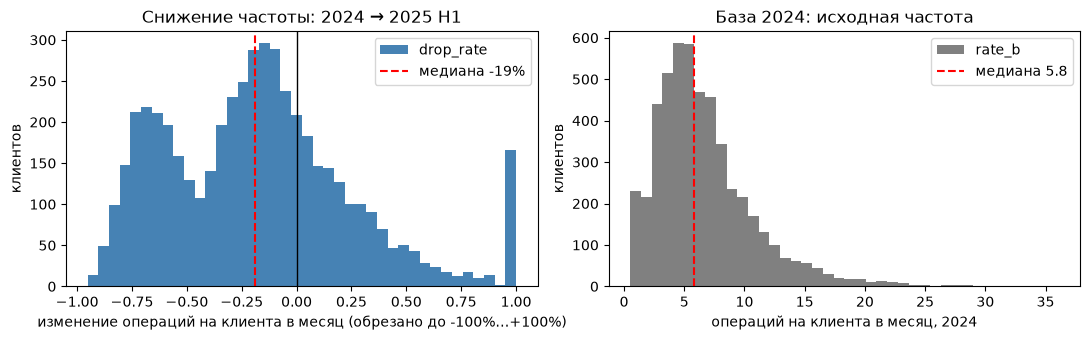

In [199]:
# ===== 3. Насколько сильно упала частота и у кого =====
el = client_activity[client_activity['eligible']].copy()

q = [.1, .25, .5, .75, .9]
print('изменение числа операций на клиента в месяц (2024 -> 2025 H1):')
print(pd.DataFrame({
    'drop_rate (2024 целиком)': el['drop_rate'].quantile(q),
    'drop_l4l (2024 H1)':       el['drop_l4l'].quantile(q),
}).round(2).to_string())

print(f"\nмедиана {el['drop_rate'].median():.1%}, like-for-like {el['drop_l4l'].median():.1%}; "
      f"рост частоты показали {(el['drop_rate'] > 0).mean():.1%} клиентов")

THRESHOLDS = [0.1, 0.2, 0.3, 0.5, 0.7]
print(pd.DataFrame({
    'снижение не меньше, %': [int(t * 100) for t in THRESHOLDS],
    'клиентов': [(el['drop_rate'] <= -t).sum() for t in THRESHOLDS],
    'доля от сравнимых, %': [round((el['drop_rate'] <= -t).mean() * 100, 1) for t in THRESHOLDS],
}).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))

el['drop_rate'].clip(-1, 1).plot.hist(bins=40, ax=ax[0], color='steelblue')
ax[0].axvline(0, color='black', lw=1)
ax[0].axvline(el['drop_rate'].median(), color='red', ls='--', lw=1.5,
              label=f'медиана {el["drop_rate"].median():.0%}')
ax[0].set_xlabel('изменение операций на клиента в месяц (обрезано до -100%…+100%)')
ax[0].set_ylabel('клиентов')
ax[0].set_title('Снижение частоты: 2024 → 2025 H1')
ax[0].legend()

el['rate_b'].plot.hist(bins=40, ax=ax[1], color='gray')
ax[1].axvline(el['rate_b'].median(), color='red', ls='--', lw=1.5,
              label=f'медиана {el["rate_b"].median():.1f}')
ax[1].set_xlabel('операций на клиента в месяц, 2024')
ax[1].set_ylabel('клиентов')
ax[1].set_title('База 2024: исходная частота')
ax[1].legend()

plt.tight_layout()


period       всего 2024  всего 2025 H1  в месяц, 2024  в месяц, 2025 H1  изменение, %
channel                                                                              
Карта            214946          77971        17912.0           12995.0         -27.5
СБП               71555          25678         5963.0            4280.0         -28.2
Онлайн-банк       61469          25886         5122.0            4314.0         -15.8
Токен             57710          38036         4809.0            6339.0          31.8

доля цифровых каналов у сравнимых клиентов: 46.6% в 2024 -> 52.0% в 2025 H1


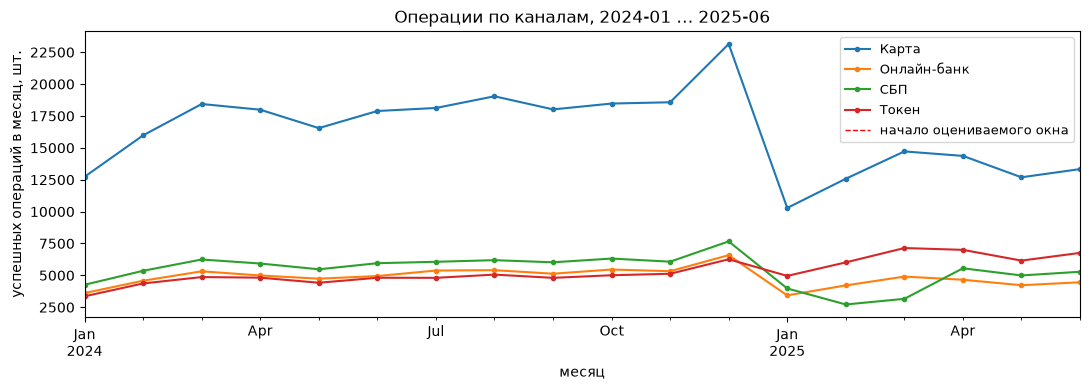

In [200]:
# ===== 4. За счёт чего: каналы оплаты =====
ops_by_channel = (df_act.groupby(['month', 'channel'], observed=True).size()
                  .unstack(fill_value=0).sort_index())

ax = ops_by_channel.plot(figsize=(11, 4), marker='o', markersize=3)
ax.axvline(ops_by_channel.index.get_loc(pd.Period('2025-01', 'M')) - 0.5,
           color='red', ls='--', lw=1, label='начало оцениваемого окна')
ax.set_xlabel('месяц')
ax.set_ylabel('успешных операций в месяц, шт.')
ax.set_title('Операции по каналам, 2024-01 … 2025-06')
ax.legend(fontsize=9)
plt.tight_layout()

chan = (df_act.groupby(['channel', 'period'], observed=True).size()
        .unstack(fill_value=0)
        .rename(columns={'2024': 'всего 2024', '2025 H1': 'всего 2025 H1'}))
chan['в месяц, 2024']    = (chan['всего 2024'] / BASE_MONTHS).round(0)
chan['в месяц, 2025 H1'] = (chan['всего 2025 H1'] / EVAL_MONTHS).round(0)
chan['изменение, %']     = ((chan['в месяц, 2025 H1'] / chan['в месяц, 2024'] - 1) * 100).round(1)
print(chan.sort_values('в месяц, 2024', ascending=False).to_string())

print(f"\nдоля цифровых каналов у сравнимых клиентов: "
      f"{client_activity.loc[client_activity['eligible'], 'digital_share_b'].mean():.1%} в 2024 -> "
      f"{client_activity.loc[client_activity['eligible'], 'digital_share_e'].mean():.1%} в 2025 H1")


period               всего 2024  всего 2025 H1  в месяц, 2024  в месяц, 2025 H1  изменение, %
category                                                                                     
Продукты                 106670          44409         8889.0            7402.0         -16.7
Кафе и рестораны          52031          22624         4336.0            3771.0         -13.0
Транспорт                 49476          16671         4123.0            2778.0         -32.6
Одежда и обувь            40800          17737         3400.0            2956.0         -13.1
АЗС                       37184          15849         3099.0            2642.0         -14.7
Связь и интернет          31535          13158         2628.0            2193.0         -16.6
Развлечения и досуг       30419          13077         2535.0            2180.0         -14.0
Аптеки                    29235          12127         2436.0            2021.0         -17.0
Онлайн-сервисы            28330          11919         2361.

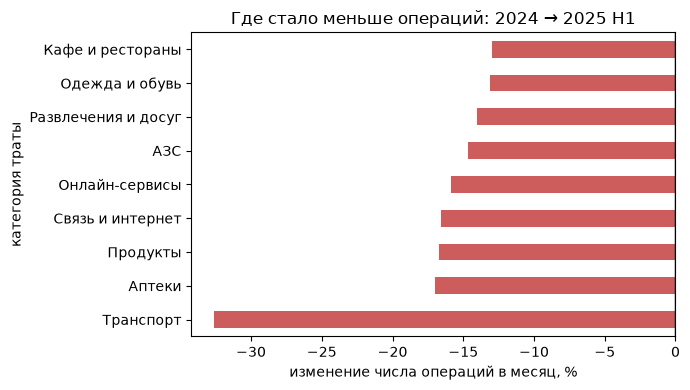

In [201]:
# ===== 5. За счёт чего: категории трат =====
cat = (df_act.groupby(['category', 'period'], observed=True).size()
       .unstack(fill_value=0)
       .rename(columns={'2024': 'всего 2024', '2025 H1': 'всего 2025 H1'}))
cat['в месяц, 2024']    = (cat['всего 2024'] / BASE_MONTHS).round(0)
cat['в месяц, 2025 H1'] = (cat['всего 2025 H1'] / EVAL_MONTHS).round(0)
cat['изменение, %']     = ((cat['в месяц, 2025 H1'] / cat['в месяц, 2024'] - 1) * 100).round(1)
cat = cat.sort_values('в месяц, 2024', ascending=False)
print(cat.to_string())

ax = cat['изменение, %'].sort_values().plot.barh(figsize=(7, 4), color='indianred')
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('изменение числа операций в месяц, %')
ax.set_ylabel('категория траты')
ax.set_title('Где стало меньше операций: 2024 → 2025 H1')
plt.tight_layout()


In [202]:
# ===== 6. Форма падения и сохранение клиентской таблицы =====
# «Сошло на нет к концу периода» — это не то же, что «стало реже весь период».
first3 = df_act[(df_act['period'] == '2025 H1') & (df_act['month'] <= pd.Period('2025-03', 'M'))]
last3  = df_act[(df_act['period'] == '2025 H1') & (df_act['month'] >= pd.Period('2025-04', 'M'))]

client_activity = (client_activity
                   .join(first3.groupby('client_id', observed=True).size().rename('ops_first3'))
                   .join(last3.groupby('client_id', observed=True).size().rename('ops_last3')))
client_activity[['ops_first3', 'ops_last3']] = client_activity[['ops_first3', 'ops_last3']].fillna(0)

client_activity['fade_out']  = (client_activity['ops_first3'] > 0) & (client_activity['ops_last3'] == 0)
client_activity['tail_drop'] = np.where(client_activity['ops_first3'] > 0,
                                        client_activity['ops_last3'] / client_activity['ops_first3'] - 1, np.nan)

mask = client_activity['eligible']
print(f"сошло на нет к концу 2025 H1: {client_activity.loc[mask, 'fade_out'].sum():,} "
      f"({client_activity.loc[mask, 'fade_out'].mean():.1%} от сравнимых)")
print(f"медианное изменение за последние 3 месяца против первых 3: "
      f"{client_activity.loc[mask, 'tail_drop'].median():.1%}")

client_activity.index.name = 'client_id'
client_activity.to_csv('../../data/client_activity.csv')
print(f"\nclient_activity: {client_activity.shape[0]:,} клиентов × {client_activity.shape[1]} признаков "
      f"-> ../../data/client_activity.csv")


сошло на нет к концу 2025 H1: 70 (1.4% от сравнимых)
медианное изменение за последние 3 месяца против первых 3: 11.1%

client_activity: 5,634 клиентов × 45 признаков -> ../../data/client_activity.csv


### Анализ активности

### Анализ